# GIST bulk TCR reanalysis in R: raw exports to figures

Select **R (datascience)** in WSL VS Code and run all cells in order. Each figure section contains its calculation, drawing code, and plot output. Main Figure 3A-G precedes S-TCR1-7. All code is included in this notebook; no existing figure or result table is loaded.

**Cohort:** exclude uncertain HG610-labeled PBMC and sparse HG606 tumor. Retain HG610 and HG624 tumors as unpaired specimens. Matched patients are HG585/HG589 (Res) and HG590/HG607 (UT).

**Filter and units:** preserve the original annotation filter as `data_filter_original`; require `sequenceStatus == "In"` for active analyses. Counts are estimated templates. Clonotypes use CDR3 amino acid, V/D/J calls, and CDR3 length within specimen.

**Inputs/outputs:** place the 12 immunoSEQ exports in `data/TCR_full_data/`, or set `GIST_TCR_INPUT_DIR`. Outputs go to `reproduced_outputs_R/` beside the notebook, or `GIST_TCR_R_OUTPUT_DIR`. Figures use 20-28 pt text and separate TXT legends. Treemap plotting panels are 90 x 90 mm.

**Scope:** complete bulk TCR workflow, including optional S-TCR5-7. Flow-cytometry Figure 3H-I and unrelated RNA-seq/survival analyses are outside this notebook. R uses its own seeded random stream, so individual sampling draws need not equal the Python draws.

## Setup and shared calculation/export helpers

Tables stay in memory and are also exported. Figures are drawn directly from calculated data. Fisher tests are two-sided; BH correction is applied within the stated comparison family. R's native hypergeometric generator is used for sampling without replacement.

In [1]:
suppressPackageStartupMessages({
    library(dplyr); library(tidyr); library(ggplot2); library(ggalluvial)
    library(treemapify); library(patchwork); library(jsonlite); library(digest)
    library(grid)
})
options(warn=1, repr.plot.res=100, repr.plot.width=12, repr.plot.height=8)
SEED <- 20261001L; REPS <- 1000L
RNGkind("Mersenne-Twister", "Inversion", "Rejection"); set.seed(SEED)
notebook_dir <- normalizePath(getwd(), winslash="/", mustWork=TRUE)
ancestors <- notebook_dir
while (dirname(tail(ancestors,1)) != tail(ancestors,1)) ancestors <- c(ancestors,dirname(tail(ancestors,1)))
input_dir <- Sys.getenv("GIST_TCR_INPUT_DIR", "")
if (!nzchar(input_dir)) {
    candidates <- file.path(ancestors,"data/TCR_full_data")
    input_dir <- candidates[dir.exists(candidates)][1]
}
if (is.na(input_dir) || !dir.exists(input_dir)) stop("Set GIST_TCR_INPUT_DIR to the 12 immunoSEQ exports.")
input_dir <- normalizePath(input_dir,winslash="/",mustWork=TRUE)
OUT_ROOT <- Sys.getenv("GIST_TCR_R_OUTPUT_DIR",file.path(notebook_dir,"reproduced_outputs_R"))
started_empty <- !dir.exists(OUT_ROOT) || !length(list.files(OUT_ROOT,recursive=TRUE,all.files=TRUE))
for (sub in c("source_data/Figure3_regenerated","results/main_figure3","results/reviewer_requested",
              "results/optional_analyses","working/previews","logs"))
    dir.create(file.path(OUT_ROOT,sub),recursive=TRUE,showWarnings=FALSE)
OUT_ROOT <- normalizePath(OUT_ROOT,winslash="/",mustWork=TRUE)
COUNT <- "count (templates/reads)"
KEY <- c("aminoAcid","vGeneName","dGeneName","jGeneName","cdr3Length")
GENES <- c("TCRDV01-01","TCRDV02-01","TCRDV03-01")
GSHORT <- c("TRDV1","TRDV2","TRDV3")
KELLY <- setNames(c("#FFB300","#803E75","#FF6800"),GENES)
GROUP_COLORS <- c(Res="#F8766D",UT="#00BFC4")
SUP_COLORS <- c(UT="#3575A8",Res="#D88735")
PAIRS <- c("HG585","HG589","HG590","HG607")
DONORS <- c("HG590","HG607","HG610","HG585","HG589","HG624")
EXCLUDED <- c(HG606_UT_Tumor="Sparse sampling; author confirmed",
              HG610_UT_PBMC="Uncertain sample identity; exclusion authorized")
FONT <- "DejaVu Sans"
source_tables <- new.env(parent=emptyenv()); figures <- list(); figure_order <- character()
input_manifest <- list(); figure_audit <- list(); treemap_audit <- list()
write_json_record <- function(x,name) jsonlite::write_json(x,file.path(OUT_ROOT,name),pretty=TRUE,auto_unbox=TRUE,na="null",digits=16)
save_table <- function(x,name) {
    x <- as.data.frame(x); source_tables[[name]] <- x
    path <- file.path(OUT_ROOT,"source_data",paste0(name,".tsv"))
    dir.create(dirname(path),recursive=TRUE,showWarnings=FALSE)
    write.table(x,path,sep="\t",quote=FALSE,row.names=FALSE,na="NA")
    invisible(x)
}
source_table <- function(name) {
    if (!exists(name,envir=source_tables,inherits=FALSE)) stop("Run the calculation for ",name," first.")
    source_tables[[name]]
}
save_main <- function(x,name) save_table(x,paste0("Figure3_regenerated/",name))
compact_gene <- function(x) gsub("TCRD([VDJ])0*([0-9]+)-[0-9]+","\\1\\2",x)
vdj_name <- function(d) paste0(compact_gene(d$vGeneName),compact_gene(d$dGeneName),compact_gene(d$jGeneName))
clonotype_key <- function(d) do.call(paste,c(d[KEY],sep="|"))
repertoire_metrics <- function(counts,genes) {
    f <- counts/sum(counts); keep <- counts>0
    c(retained_counts=sum(counts),richness=sum(keep),simpson_dominance=sum(f^2),
      shannon_entropy=-sum(f[keep]*log(f[keep])),fraction_clones_gt10=sum(counts>10)/sum(keep),
      setNames(vapply(GENES,function(g) sum(f[genes==g]),numeric(1)),GSHORT))
}
clone_fisher <- function(a,b) {
    na <- sum(a); nb <- sum(b)
    vapply(seq_along(a),function(i) fisher.test(matrix(c(a[i],na-a[i],b[i],nb-b[i]),ncol=2),alternative="two.sided")$p.value,numeric(1))
}
safe_cor <- function(a,b) if(length(a)>1 && sd(a)>0 && sd(b)>0) cor(a,b,method="spearman") else NA_real_
exact_paired <- function(delta) {
    signs <- as.matrix(expand.grid(rep(list(c(-1,1)),length(delta))))
    values <- as.vector(signs %*% delta)/length(delta)
    mean(abs(values)>=abs(mean(delta))-1e-12)
}
exact_group <- function(a,b) {
    v <- c(a,b); assignments <- combn(seq_along(v),length(a),simplify=FALSE)
    effects <- vapply(assignments,function(i) mean(v[i])-mean(v[-i]),numeric(1))
    mean(abs(effects)>=abs(mean(a)-mean(b))-1e-12)
}
theme_tcr <- function() theme_classic(base_size=22,base_family=FONT)+theme(
    text=element_text(size=22),axis.title=element_text(size=22),axis.text=element_text(size=20),
    legend.title=element_text(size=22),legend.text=element_text(size=20),
    plot.title=element_text(size=24,hjust=.5),plot.subtitle=element_text(size=20),
    plot.tag=element_text(size=28,face="bold"),strip.text=element_text(size=22),
    plot.margin=margin(8,10,8,8))
theme_set(theme_tcr())
update_geom_defaults("text",list(size=20/.pt)); update_geom_defaults("label",list(size=20/.pt))
as_draw <- function(p) local({ object <- p; function(new_page=TRUE) {
    if (new_page) grid.newpage()
    if (inherits(object,c("ggplot","patchwork"))) print(object,newpage=FALSE) else grid.draw(object)
}})
emit_figure <- function(id,plot=NULL,draw=NULL,width,height,caption,scope="main") {
    if (is.null(draw)) draw <- as_draw(plot)
    dest <- switch(scope,main="main_figure3",requested="reviewer_requested",optional="optional_analyses")
    pdf_path <- file.path(OUT_ROOT,"results",dest,paste0(id,".pdf"))
    cairo_pdf(pdf_path,width=width/25.4,height=height/25.4,family=FONT,onefile=TRUE)
    draw(); dev.off()
    ragg::agg_png(file.path(OUT_ROOT,"working/previews",paste0(id,".png")),width=width,height=height,units="mm",res=100)
    draw(); dev.off()
    figures[[id]] <<- list(draw=draw,width=width,height=height,caption=caption,scope=scope,file=pdf_path)
    figure_order <<- c(figure_order,id)
    figure_audit[[id]] <<- list(width_mm=width,height_mm=height,font_family=FONT)
    options(repr.plot.width=width/25.4,repr.plot.height=height/25.4)
    draw()
    invisible(NULL)
}
treemap_plot <- function(d) ggplot(d,aes(area=count,fill=factor(vGeneName,levels=GENES)))+
    geom_treemap(colour="black",size=.25)+scale_fill_manual(values=KELLY,drop=FALSE)+
    theme_void()+theme(legend.position="none",plot.margin=margin(0,0,0,0))
grid_text_mm <- function(label,x,y,size=22,...) grid.text(label,x=unit(x,"mm"),y=unit(y,"mm"),gp=gpar(fontsize=size,fontfamily=FONT),...)
place_plot_mm <- function(p,x,y,w,h) {
    pushViewport(viewport(x=unit(x,"mm"),y=unit(y,"mm"),width=unit(w,"mm"),height=unit(h,"mm"),just=c("left","bottom")))
    print(p,newpage=FALSE); popViewport()
}
kelly_legend <- function(x,y) for(i in seq_along(GENES)) {
    grid.rect(x=unit(x+(i-1)*70,"mm"),y=unit(y,"mm"),width=unit(6,"mm"),height=unit(6,"mm"),gp=gpar(fill=KELLY[i],col="black"))
    grid_text_mm(GSHORT[i],x+7+(i-1)*70,y,size=22,just="left")
}
cat(R.version.string,"\nKernel: R (datascience)\nInput:",input_dir,"\nOutput:",OUT_ROOT,"\nStarted empty:",started_empty,"\n")

R version 4.5.3 (2026-03-11) 
Kernel: R (datascience)
Input: /mnt/c/yuntian/necessary/Upenn/Nancy/project/gist/data/TCR_full_data 
Output: /mnt/c/yuntian/necessary/Upenn/Nancy/project/gist/revision/submission/reproduced_outputs_R 
Started empty: TRUE 


## Raw data, original/productive filters, and cohort

Preserve the original nonempty amino-acid/V/D/J filter and TCRA exclusion. Add status In for productive retention, then sum templates by clonotype within specimen. Retain all 12 exports in QC records, but only ten specimens and four complete pairs in the specified analyses. All later cells use these in-memory data.

In [2]:
paths <- sort(list.files(input_dir,pattern="_ydT[.]tsv$",full.names=TRUE))
stopifnot(length(paths)==12)
tables <- list(); qc_rows <- list(); filtering_rows <- list()
for (path in paths) {
    d <- read.delim(path,check.names=FALSE,stringsAsFactors=FALSE,na.strings=NULL,quote="",comment.char="")
    d[[COUNT]] <- as.numeric(d[[COUNT]])
    stopifnot(all(d[[COUNT]]>0),all(d[[COUNT]]%%1==0))
    sample <- sub("_ydT[.]tsv$","",basename(path)); info <- strsplit(sample,"_",fixed=TRUE)[[1]]
    data_filter_original <- !grepl("TCRA",d$vGeneName)&!grepl("TCRA",d$jGeneName)&
        Reduce(`&`,lapply(d[KEY[1:4]],function(x) !is.na(x)&nzchar(x)))
    productive <- d$sequenceStatus=="In"
    keep <- data_filter_original & productive
    aggregate_clones <- function(z) z %>% group_by(across(all_of(KEY))) %>% summarise(count=sum(.data[[COUNT]]),.groups="drop") %>% arrange(across(all_of(KEY)))
    x <- aggregate_clones(d[keep,]); legacy <- aggregate_clones(d[data_filter_original,])
    x$clone_key <- clonotype_key(x); stopifnot(!anyDuplicated(x$clone_key))
    x$sample <- sample;x$patient <- info[1];x$treatment <- info[2];x$tissue <- info[3]
    x$frequency <- x$count/sum(x$count);x$included_primary <- !sample %in% names(EXCLUDED)
    tables[[sample]] <- x
    qc_rows[[sample]] <- data.frame(sample=sample,patient=info[1],treatment=info[2],tissue=info[3],
        included_primary=!sample %in% names(EXCLUDED),exclusion_reason=if(sample %in% names(EXCLUDED)) EXCLUDED[[sample]] else "",
        export_rows=nrow(d),total_export_counts=sum(d[[COUNT]]),productive_export_rows=sum(productive),
        productive_export_counts=sum(d[[COUNT]][productive]),productive_fraction_of_export_counts=sum(d[[COUNT]][productive])/sum(d[[COUNT]]),
        retained_productive_TRD_rows=sum(keep),retained_productive_TRD_counts=sum(x$count),retained_clonotypes=nrow(x),
        legacy_stop_rows_removed=sum(data_filter_original&d$sequenceStatus=="Stop"),
        legacy_stop_counts_removed=sum(d[[COUNT]][data_filter_original&d$sequenceStatus=="Stop"]),
        legacy_clonotypes_above_1000=sum(legacy$count>1000),legacy_counts_above_1000=sum(legacy$count[legacy$count>1000]),
        counts_equal_estimatedNumberGenomes=isTRUE(all.equal(d[[COUNT]],as.numeric(d$estimatedNumberGenomes))),
        count_units="estimated template counts; interpretation authorized by Yuntian",
        raw_sequencing_reads="not supplied",counting_method_version="not supplied")
    filtering_rows[[sample]] <- data.frame(sample=sample,patient=info[1],treatment=info[2],tissue=info[3],
        legacy_clonotypes=nrow(legacy),revised_clonotypes=nrow(x),legacy_counts=sum(legacy$count),revised_counts=sum(x$count))
    input_manifest[[sample]] <- list(file=basename(path),sha256=digest(path,algo="sha256",file=TRUE),bytes=file.info(path)$size)
}
qc <- bind_rows(qc_rows);all_clones <- bind_rows(tables);clones <- filter(all_clones,included_primary)
samples <- sort(unique(clones$sample))
paired <- clones %>% distinct(patient,tissue) %>% count(patient) %>% filter(n==2) %>% pull(patient)
stopifnot(length(samples)==10,setequal(paired,PAIRS))
observed <- bind_rows(lapply(samples,function(s) {
    x <- tables[[s]]; cbind(x[1,c("sample","patient","treatment","tissue")],as.data.frame(as.list(repertoire_metrics(x$count,x$vGeneName))))
}))
save_table(qc,"sample_QC");save_table(bind_rows(filtering_rows),"filtering_audit")
save_table(all_clones,"productive_TRD_clonotypes");save_table(observed,"observed_sample_metrics")
specimen_order <- unlist(lapply(DONORS,function(p) paste(p,if(p %in% c("HG585","HG589","HG624")) "Res" else "UT",c("PBMC","Tumor"),sep="_")))
specimen_order <- specimen_order[specimen_order %in% samples]
sample_labels <- setNames(gsub("_(UT|Res)_"," ",specimen_order),specimen_order)
qc[,c("sample","included_primary","retained_productive_TRD_counts","retained_clonotypes","exclusion_reason")]

sample,included_primary,retained_productive_TRD_counts,retained_clonotypes,exclusion_reason
<chr>,<lgl>,<dbl>,<int>,<chr>
HG585_Res_PBMC,TRUE,7576,698,
HG585_Res_Tumor,TRUE,2578,577,
HG589_Res_PBMC,TRUE,8281,632,
HG589_Res_Tumor,TRUE,5976,1014,
HG590_UT_PBMC,TRUE,4829,1191,
HG590_UT_Tumor,TRUE,4379,2035,
HG606_UT_Tumor,FALSE,1323,174,Sparse sampling; author confirmed
HG607_UT_PBMC,TRUE,6789,1114,
HG607_UT_Tumor,TRUE,4206,1148,


## Figure 3A - Clonotype abundance bins

Bin each clonotype by template count: 1, 2-5, 6-10, 11-100, 101-1,000, and >1,000. Divide the clonotype count in each bin by all clonotypes in that specimen. Each stacked bar sums to one; the denominator counts clonotypes, not templates.

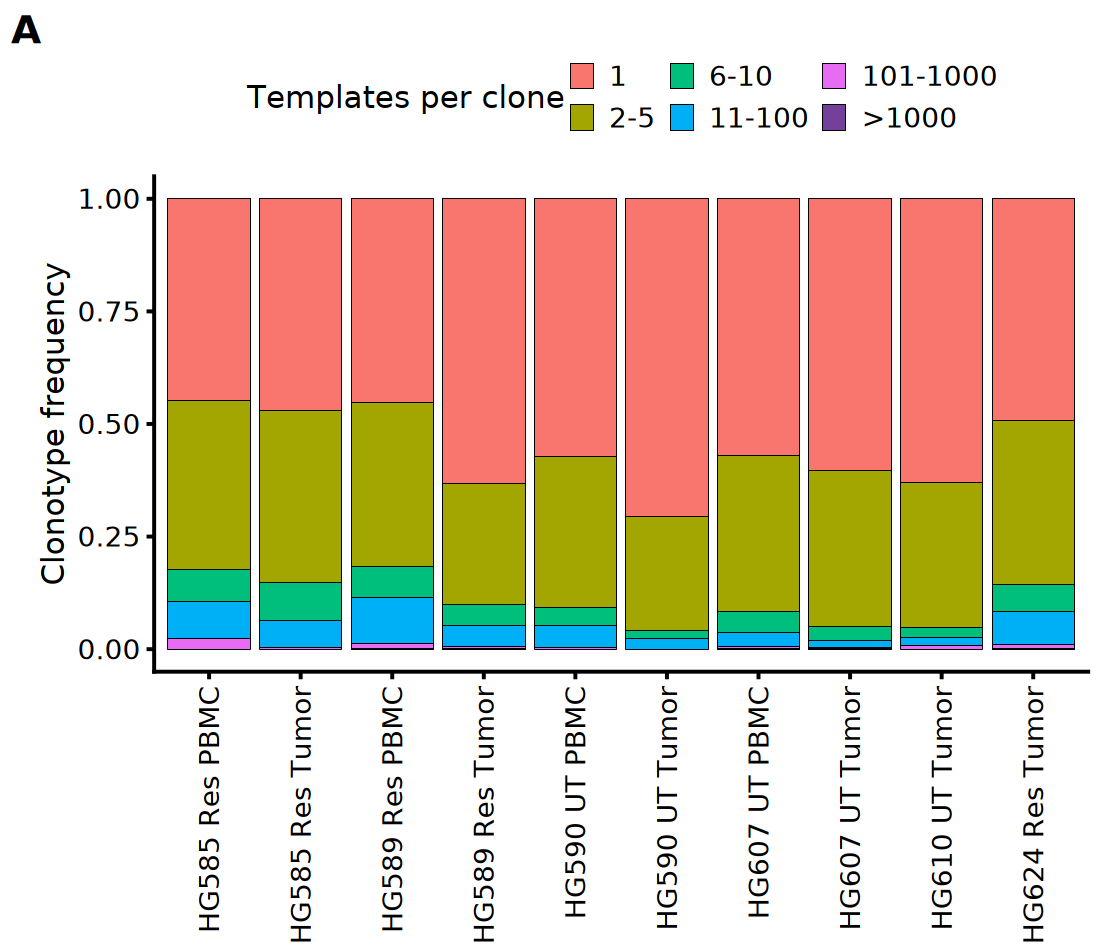

In [3]:
bin_labels <- c("1","2-5","6-10","11-100","101-1000",">1000")
bins <- c(0,1,5,10,100,1000,Inf)
expansion <- bind_rows(lapply(samples,function(s) {
    x <- tables[[s]];n <- table(cut(x$count,bins,labels=bin_labels))
    cbind(x[rep(1,6),c("sample","patient","treatment","tissue")],data.frame(count_bin=bin_labels,clonotypes=as.integer(n),fraction=as.numeric(n)/nrow(x)))
}))
save_table(expansion,"Figure3A_expansion_bins");save_main(expansion,"A_expansion_bins")
plot_a_data <- expansion %>% mutate(sample=factor(sample,levels=samples),count_bin=factor(count_bin,levels=bin_labels))
plot_A <- ggplot(plot_a_data,aes(sample,fraction,fill=count_bin))+geom_col(colour="black",linewidth=.25)+
    scale_fill_manual(values=setNames(c("#F8766D","#A3A500","#00BF7D","#00B0F6","#E76BF3","#73419A"),bin_labels))+
    scale_x_discrete(labels=function(x) gsub("_"," ",x))+labs(x=NULL,y="Clonotype frequency",fill="Templates per clone",tag="A")+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="top")+guides(fill=guide_legend(nrow=2))
emit_figure("Figure3A",plot_A,width=280,height=240,
    caption="A. Fractions of distinct productive clonotypes in template-count bins for ten included specimens. The open-ended >1,000 bin retains the largest clones.")

## Figure 3B - Highly expanded clonotypes

Divide the number of clonotypes with >10 templates by all retained clonotypes in each matched specimen. Connect each patient's PBMC and tumor. Apply an exact two-sided paired Wilcoxon signed-rank test across four patient pairs and print its P value.

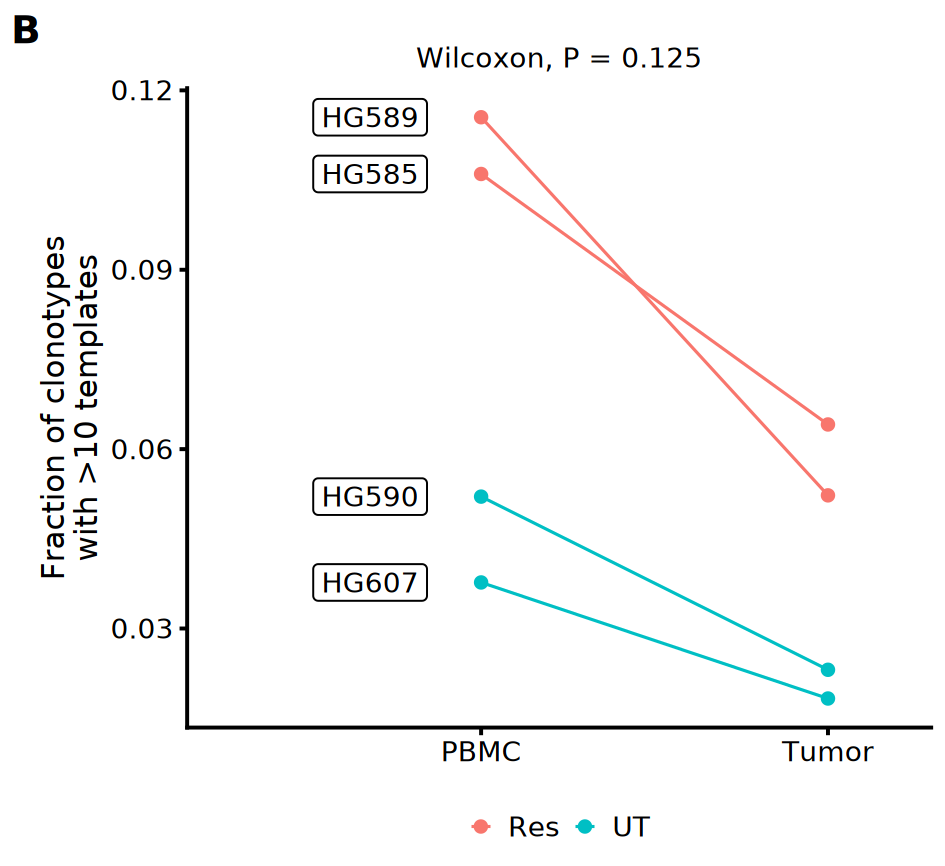

In [4]:
B <- observed %>% filter(patient %in% PAIRS) %>% select(sample,patient,treatment,tissue,fraction_clones_gt10)
wide_B <- B %>% select(patient,tissue,fraction_clones_gt10) %>% pivot_wider(names_from=tissue,values_from=fraction_clones_gt10) %>% arrange(patient)
B_p <- wilcox.test(wide_B$Tumor,wide_B$PBMC,paired=TRUE,alternative="two.sided",exact=TRUE)$p.value
save_main(B,"B_high_abundance")
save_main(data.frame(test="two-sided exact paired Wilcoxon signed-rank",n_pairs=nrow(wide_B),p=B_p,threshold=">10 estimated templates"),"B_statistics")
B$x <- match(B$tissue,c("PBMC","Tumor"))
plot_B <- ggplot(B,aes(x,fraction_clones_gt10,colour=treatment,group=patient))+
    geom_line(linewidth=.8)+geom_point(size=3)+geom_label(data=filter(B,tissue=="PBMC"),aes(label=patient),
        nudge_x=-.32,colour="black",fill="white",size=20/.pt,show.legend=FALSE)+
    scale_colour_manual(values=GROUP_COLORS)+scale_x_continuous(breaks=1:2,labels=c("PBMC","Tumor"),limits=c(.25,2.2))+
    labs(x=NULL,y="Fraction of clonotypes\nwith >10 templates",colour=NULL,tag="B",title=sprintf("Wilcoxon, P = %.3f",B_p))+
    theme(legend.position="bottom",plot.title=element_text(size=20))
emit_figure("Figure3B",plot_B,width=240,height=220,
    caption=sprintf("B. Fraction of distinct clonotypes with >10 estimated templates. Lines connect matched specimens. Exact two-sided paired Wilcoxon P=%.3f; n=4 pairs.",B_p))

## Figure 3C - V-gene usage

Within each matched specimen, divide templates assigned to each TRDV gene by all retained productive templates. Bars are the median of two donors per tissue-treatment group. Points and connecting lines preserve patient pairing. These are V-gene, not constant-region, measurements.

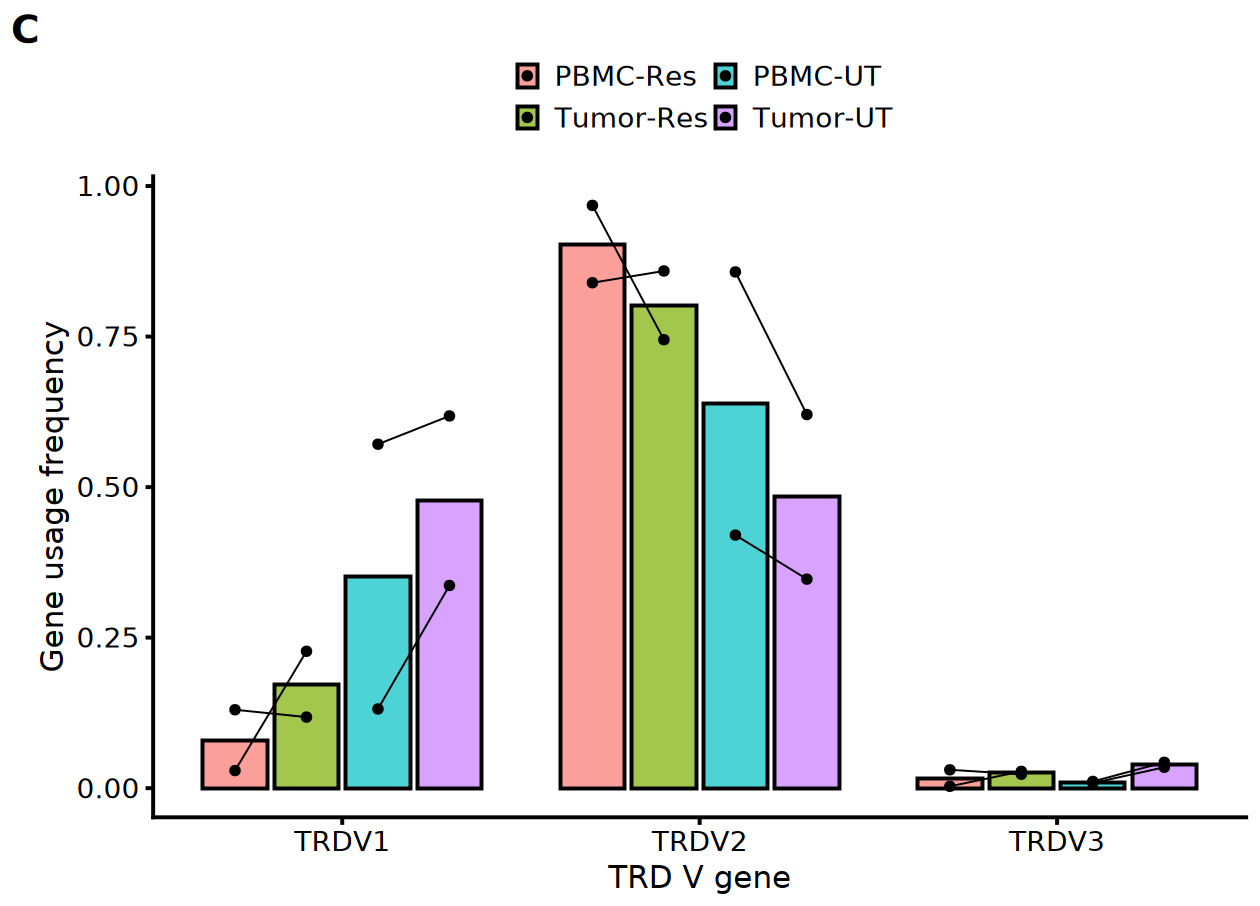

In [5]:
C <- observed %>% filter(patient %in% PAIRS) %>% select(sample,patient,treatment,tissue,all_of(GSHORT))
save_main(C,"C_V_gene_frequencies")
save_table(observed %>% select(sample,patient,treatment,tissue,all_of(GSHORT)),"Figure3C_V_gene_usage")
c_long <- C %>% pivot_longer(all_of(GSHORT),names_to="gene",values_to="frequency") %>%
    mutate(group=factor(paste(tissue,treatment,sep="-"),levels=c("PBMC-Res","Tumor-Res","PBMC-UT","Tumor-UT")),
           x=match(gene,GSHORT)+(as.integer(group)-2.5)*.2)
plot_C <- ggplot(c_long,aes(x,frequency,fill=group))+stat_summary(fun=median,geom="col",width=.18,alpha=.7,colour="black")+
    geom_line(aes(group=interaction(patient,gene)),colour="black",linewidth=.5)+geom_point(colour="black",size=2)+
    scale_x_continuous(breaks=1:3,labels=GSHORT)+
    scale_fill_manual(values=c("#F8766D","#7CAE00","#00BFC4","#C77CFF"))+
    labs(x="TRD V gene",y="Gene usage frequency",fill=NULL,tag="C")+
    theme(legend.position="top")+guides(fill=guide_legend(nrow=2))
emit_figure("Figure3C",plot_C,width=320,height=230,
    caption="C. Template-weighted TRDV frequencies in four matched donors. Bars are medians; points represent donors and lines retain pairing. Each specimen's retained productive template total is its denominator.")

## Figure 3D - Pooled bulk TCR treemaps

Pool specimen-specific clonotype rows within the four tissue-treatment groups of the matched donors. Rectangle area is proportional to the group's template counts; color denotes V gene. Identical sequences from different specimens stay separate rectangles. Draw each plotting panel at exactly 90 x 90 mm.

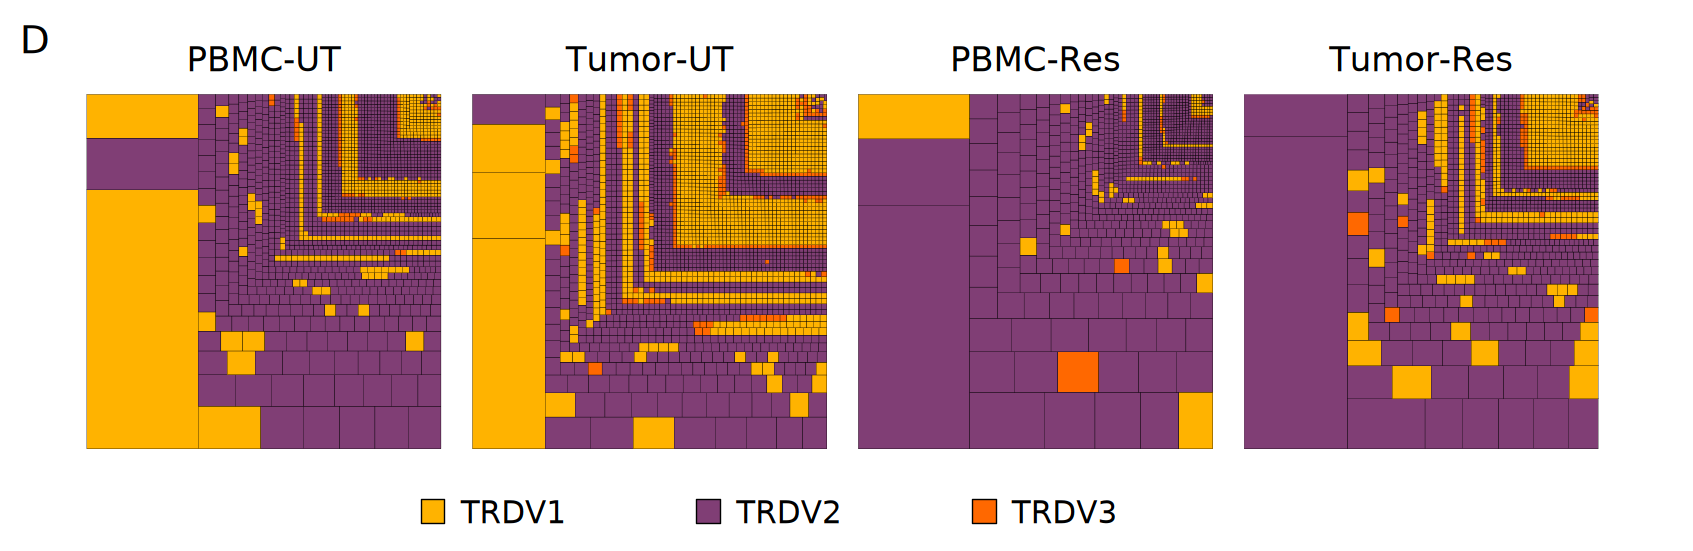

In [6]:
D <- filter(clones,patient %in% PAIRS);save_main(D,"D_matched_treemap_clonotypes")
d_groups <- data.frame(treatment=c("UT","UT","Res","Res"),tissue=c("PBMC","Tumor","PBMC","Tumor"))
d_plots <- lapply(seq_len(nrow(d_groups)),function(i) treemap_plot(filter(D,treatment==d_groups$treatment[i],tissue==d_groups$tissue[i])))
draw_D <- local({ pp <- d_plots; labels <- paste(d_groups$tissue,d_groups$treatment,sep="-");function(new_page=TRUE) {
    if(new_page) grid.newpage()
    grid_text_mm("D",5,130,size=28,just="left")
    for(i in 1:4) {x <- 22+(i-1)*98;place_plot_mm(pp[[i]],x,26,90,90);grid_text_mm(labels[i],x+45,125,size=24)}
    kelly_legend(110,10)
}})
treemap_audit$Figure3D <- data.frame(group=paste(d_groups$tissue,d_groups$treatment,sep="-"),width_mm=90,height_mm=90)
emit_figure("Figure3D",draw=draw_D,width=430,height=140,
    caption="D. Pooled bulk TCR treemaps of the four matched tissue-treatment groups. Rectangles are specimen-specific clonotypes; area is proportional to estimated templates. TRDV1 is gold, TRDV2 purple, and TRDV3 orange. Each plotting panel is 90 x 90 mm.")

## Figure 3E - Treatment-group differential expansion

Join each patient's PBMC-tumor clone union, filling nondetections with zero. Compare each clone to remaining templates pooled within treatment using two-sided Fisher tests and BH adjustment within treatment. Panel E highlights q<0.05 and raw tumor count > PBMC count. The original F/G rule instead requires higher tumor frequency relative to pooled tissue-treatment totals. Axes show ln(1 + templates).

treatment,union_clonotypes,tumor_enriched_clonotypes,tumor_enriched_FG
<chr>,<int>,<int>,<int>
Res,2528,73,75
UT,5040,33,33


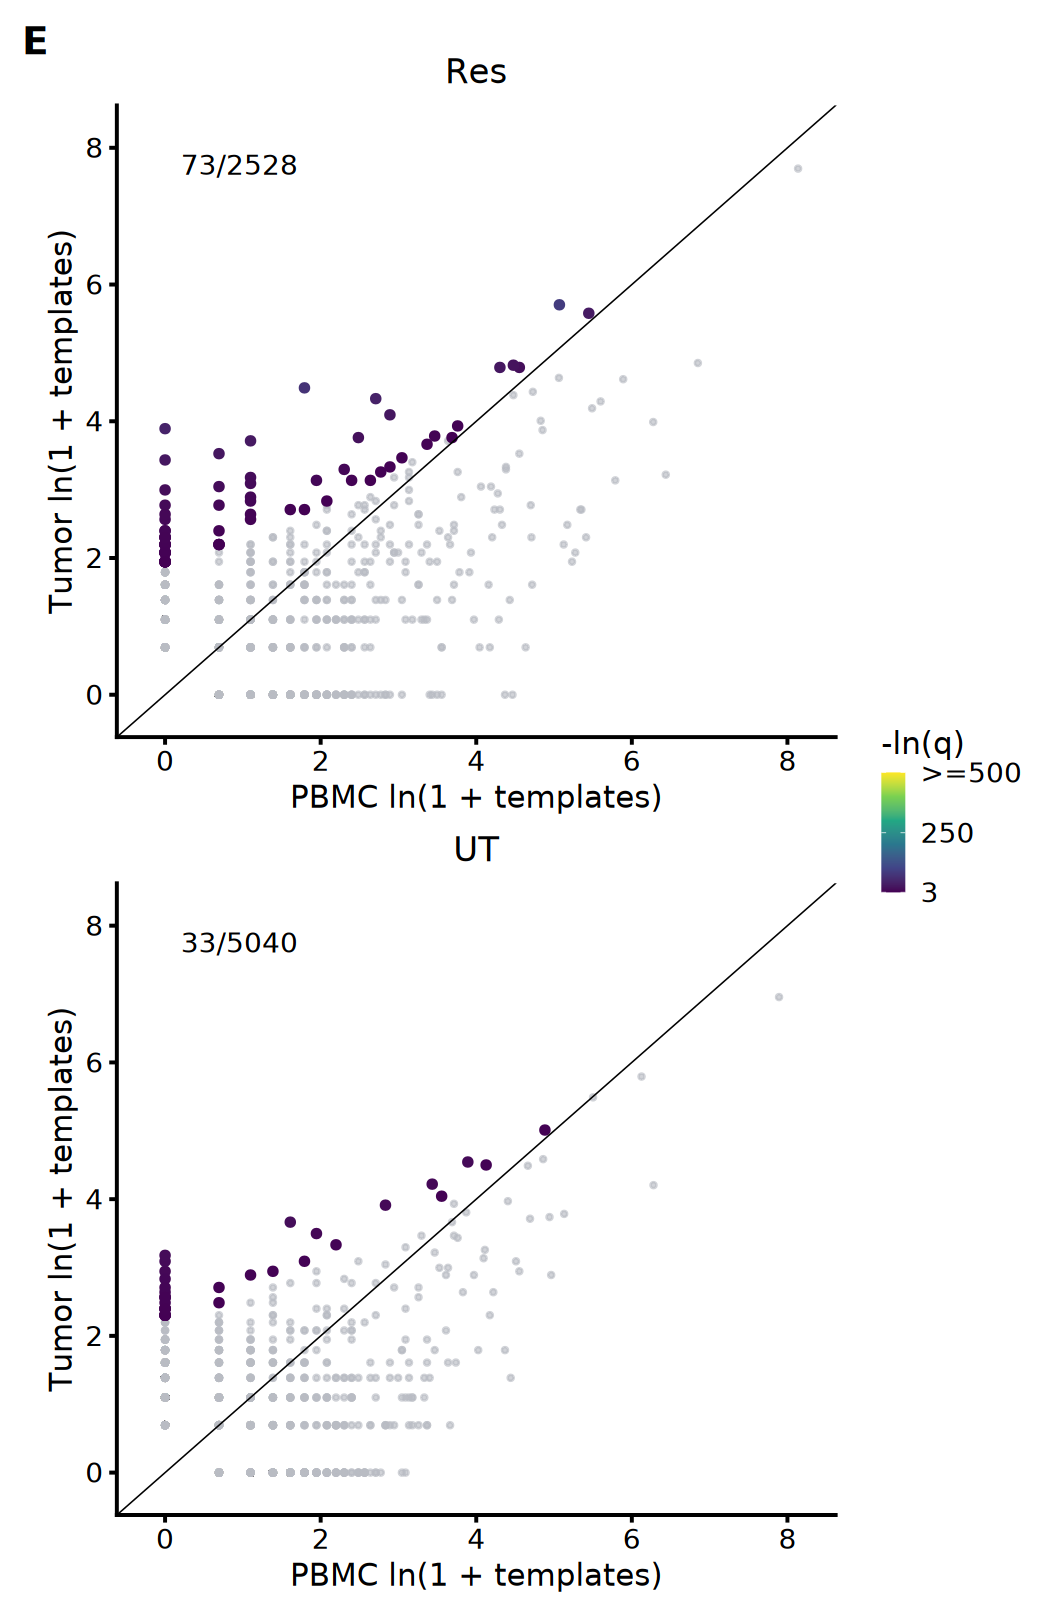

In [7]:
pair_unions <- list()
for(patient in PAIRS) {
    ss <- samples[startsWith(samples,paste0(patient,"_"))]
    a <- tables[[ss[endsWith(ss,"PBMC")]]];b <- tables[[ss[endsWith(ss,"Tumor")]]]
    u <- full_join(select(a,clone_key,count_PBMC=count),select(b,clone_key,count_Tumor=count),by="clone_key") %>%
        mutate(count_PBMC=replace_na(count_PBMC,0),count_Tumor=replace_na(count_Tumor,0)) %>% arrange(clone_key)
    u$patient <- patient;u$treatment <- a$treatment[1];pair_unions[[patient]] <- u
}
E <- bind_rows(pair_unions) %>% group_by(treatment) %>% mutate(
    p_fisher=clone_fisher(count_PBMC,count_Tumor),q_BH_within_treatment=p.adjust(p_fisher,"BH"),
    PBMC_frequency_within_treatment=count_PBMC/sum(count_PBMC),Tumor_frequency_within_treatment=count_Tumor/sum(count_Tumor)) %>% ungroup() %>%
    mutate(highlight_E=q_BH_within_treatment<.05 & count_Tumor>count_PBMC,
           tumor_enriched_FG=q_BH_within_treatment<.05 & Tumor_frequency_within_treatment>PBMC_frequency_within_treatment)
save_main(E,"E_clone_tests")
group_counts <- E %>% group_by(treatment) %>% summarise(union_clonotypes=n(),tumor_enriched_clonotypes=sum(highlight_E),tumor_enriched_FG=sum(tumor_enriched_FG),.groups="drop")
save_main(group_counts,"E_group_counts")
e_group_p <- with(group_counts,fisher.test(cbind(tumor_enriched_clonotypes,union_clonotypes-tumor_enriched_clonotypes))$p.value)
save_main(data.frame(test="Original clone-count Fisher test, UT versus Res",p=e_group_p),"E_original_group_comparison")
plot_e <- function(tr) {
    d <- filter(E,treatment==tr);sig <- filter(d,highlight_E)
    ggplot(d,aes(log1p(count_PBMC),log1p(count_Tumor)))+geom_point(colour="#B8BCC3",size=1,alpha=.65)+
        geom_point(data=sig,aes(colour=pmin(-log(pmax(q_BH_within_treatment,.Machine$double.xmin)),500)),size=2)+
        geom_abline(linewidth=.4)+scale_colour_viridis_c(name="-ln(q)",limits=c(-log(.05),500),breaks=c(-log(.05),250,500),labels=c("3","250",">=500"))+
        annotate("text",x=.2,y=7.9,label=paste0(nrow(sig),"/",nrow(d)),hjust=0,vjust=1,size=20/.pt)+
        coord_cartesian(xlim=c(-.2,8.2),ylim=c(-.2,8.2))+labs(title=tr,x="PBMC ln(1 + templates)",y="Tumor ln(1 + templates)")
}
plot_E <- ((plot_e("Res")+labs(tag="E"))/plot_e("UT"))+plot_layout(guides="collect")
emit_figure("Figure3E",plot_E,width=270,height=410,
    caption="E. Original treatment-group clone enrichment tests: two-sided Fisher with BH within treatment. Colored points have q<0.05 and raw tumor count > PBMC count. Labels are enriched/union clonotypes (Res 73/2528; UT 33/5040). Colors show -ln(q), capped at 500; axes retain zero observations with ln(1 + templates).")
group_counts

## Figure 3F - V/D/J combinations of tumor-enriched clones

Select clones passing the original frequency-based F/G rule from Figure 3E. Count each V/D/J combination in UT and Res. Each ribbon unit is one clonotype, so V, D, and J columns have equal totals. Draw the alluvial ribbons directly from these counts.

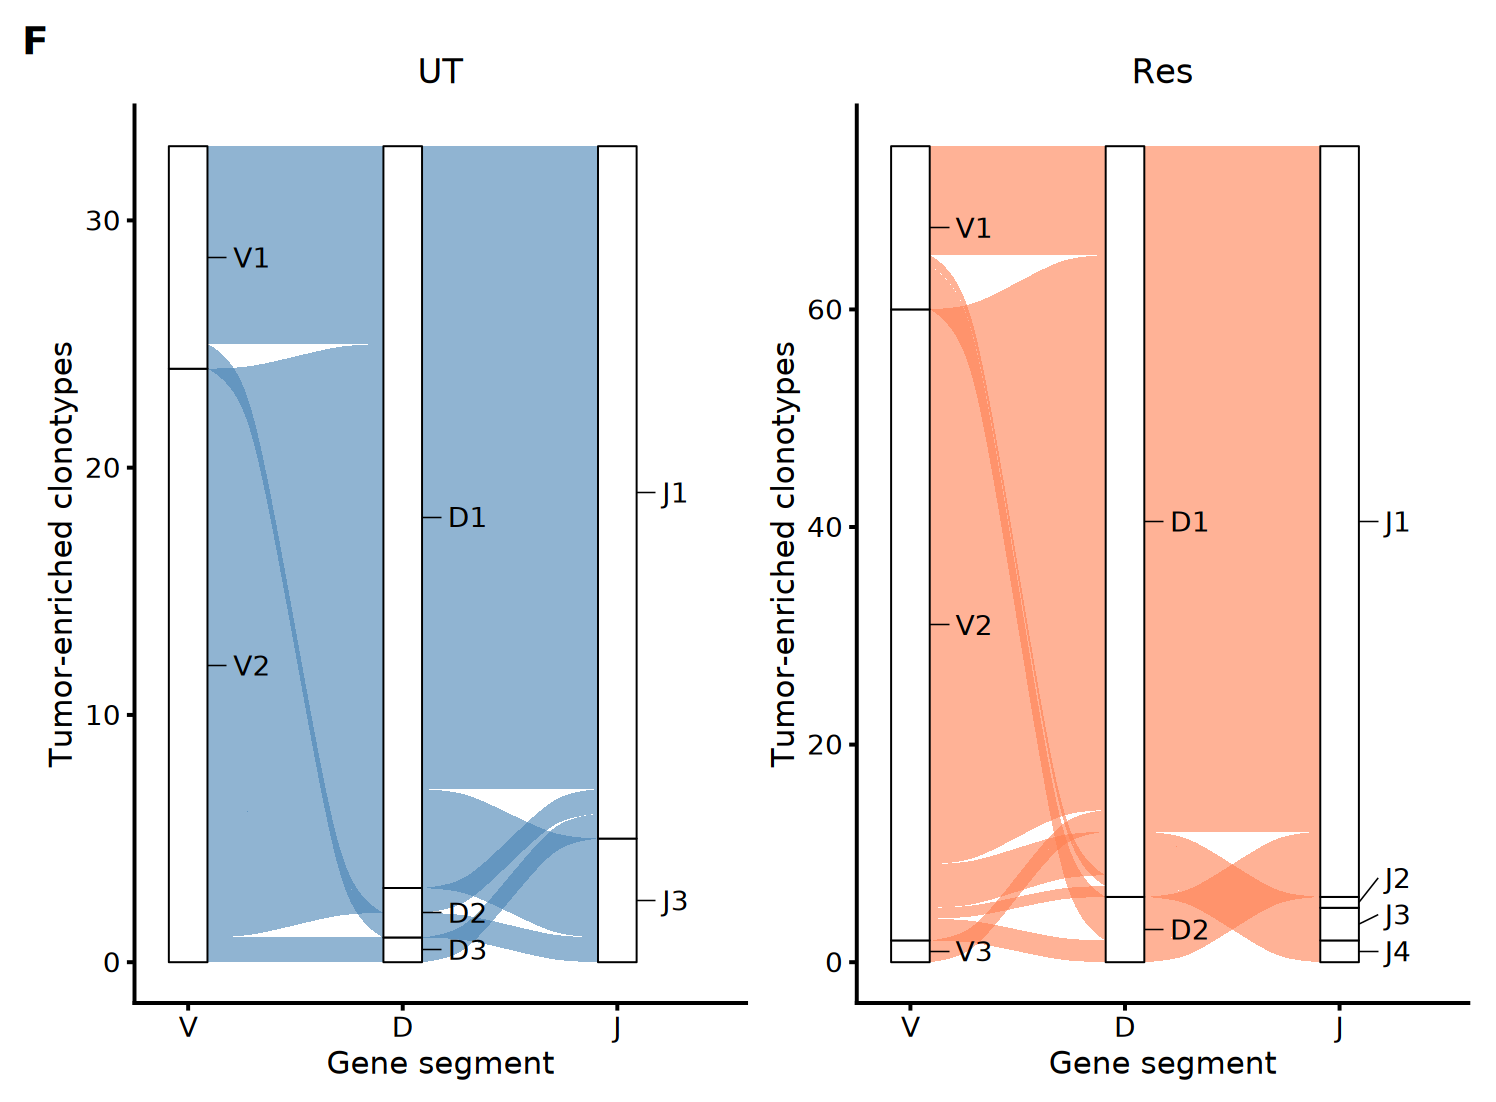

In [8]:
enriched <- filter(E,tumor_enriched_FG) %>% separate(clone_key,into=KEY,sep="\\|",remove=FALSE,convert=FALSE)
FG <- enriched %>% count(treatment,vGeneName,dGeneName,jGeneName,name="clonotypes") %>%
    group_by(treatment) %>% mutate(fraction=clonotypes/sum(clonotypes)) %>% ungroup()
save_main(FG,"F_G_tumor_enriched_VDJ")
plot_f <- function(tr) {
    d <- filter(FG,treatment==tr) %>% mutate(V=compact_gene(vGeneName),D=compact_gene(dGeneName),J=compact_gene(jGeneName))
    p <- ggplot(d,aes(y=clonotypes,axis1=V,axis2=D,axis3=J))+geom_alluvium(fill=if(tr=="UT") "steelblue" else "coral",alpha=.6,width=.18)+
        geom_stratum(width=.18,fill="white",colour="black")+
        scale_x_discrete(limits=c("V","D","J"),expand=expansion(add=c(.25,.6)))+
        labs(title=tr,x="Gene segment",y="Tumor-enriched clonotypes")
    # Place labels beside strata and separate tiny adjacent categories vertically.
    labels <- as.data.frame(ggplot_build(p)$data[[2]]) %>% select(x,y,stratum) %>% arrange(x,y)
    labels$x <- as.numeric(labels$x);labels$label_y <- labels$y
    for(axis in unique(labels$x)) {
        ix <- which(labels$x==axis)
        if(length(ix)>1) for(j in 2:length(ix))
            labels$label_y[ix[j]] <- max(labels$y[ix[j]],labels$label_y[ix[j-1]]+sum(d$clonotypes)*.045)
    }
    p+geom_segment(data=labels,aes(x=x+.09,xend=x+.18,y=y,yend=label_y),inherit.aes=FALSE,linewidth=.4)+
        geom_text(data=labels,aes(x=x+.21,y=label_y,label=stratum),inherit.aes=FALSE,hjust=0,size=20/.pt)
}
plot_F <- (plot_f("UT")+labs(tag="F"))|plot_f("Res")
emit_figure("Figure3F",plot_F,width=380,height=280,
    caption="F. V/D/J assignments of tumor-enriched clonotypes under the original F/G rule: q<0.05 and higher pooled-treatment tumor frequency. Ribbon width counts clonotypes. Totals are UT 33 and Res 75; these can differ from panel E because the direction rules differ.")

## Figure 3G - VDJ composition and Fisher tests

Divide each VDJ count by all tumor-enriched clones in that group. Tile colors show fractions and labels show counts. For each combination, compare [this combination, all others] between UT and Res using an unadjusted two-sided Fisher test. Display all P values and ns for P>=0.05; these preserve the original clone-count framework.

vGeneName,dGeneName,jGeneName,Res_clonotypes,UT_clonotypes,p_fisher,stars
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<chr>
TCRDV01-01,TCRDD01-01,TCRDJ01-01,10,8,0.1721280,
TCRDV01-01,TCRDD01-01,TCRDJ04-01,1,0,1.0000000,
TCRDV01-01,TCRDD02-01,TCRDJ01-01,4,0,0.3107931,
TCRDV02-01,TCRDD01-01,TCRDJ01-01,51,18,0.1978991,
TCRDV02-01,TCRDD01-01,TCRDJ02-01,1,0,1.0000000,
TCRDV02-01,TCRDD01-01,TCRDJ03-01,3,4,0.1970325,
TCRDV02-01,TCRDD01-01,TCRDJ04-01,1,0,1.0000000,
TCRDV02-01,TCRDD02-01,TCRDJ01-01,2,1,1.0000000,
TCRDV03-01,TCRDD01-01,TCRDJ01-01,2,0,1.0000000,


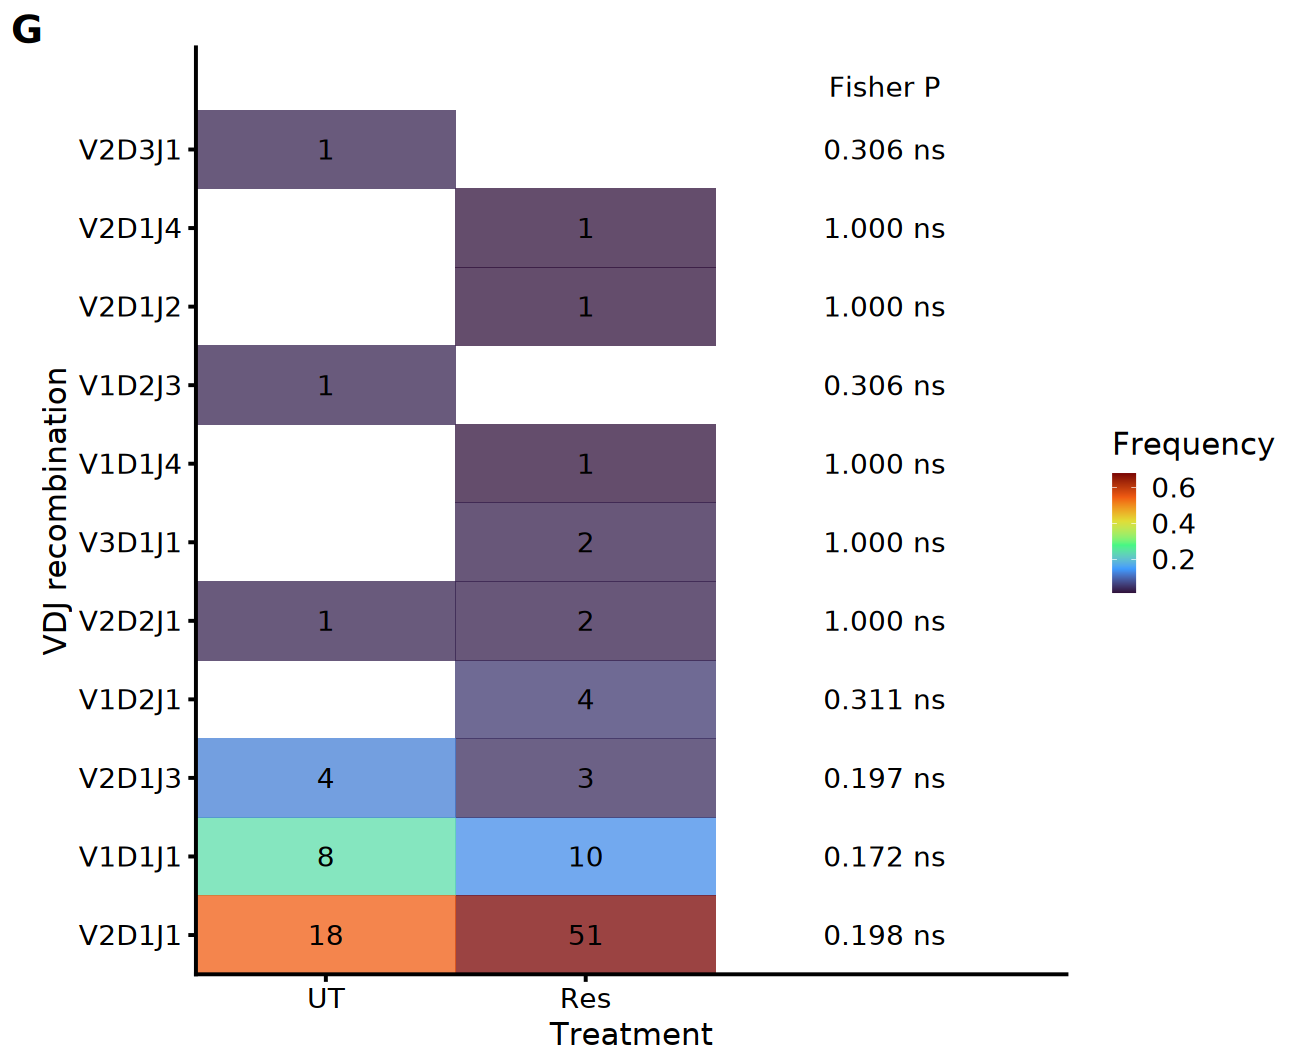

In [9]:
G_counts <- FG %>% select(treatment,vGeneName,dGeneName,jGeneName,clonotypes) %>%
    pivot_wider(names_from=treatment,values_from=clonotypes,values_fill=0)
G_tests <- G_counts %>% mutate(p_fisher=clone_fisher(Res,UT),stars=case_when(
    p_fisher<.0001~"****",p_fisher<.001~"***",p_fisher<.01~"**",p_fisher<.05~"*",TRUE~"")) %>%
    rename(Res_clonotypes=Res,UT_clonotypes=UT)
save_main(G_tests,"G_original_group_Fisher_tests")
g_test <- G_tests %>% mutate(VDJ=vdj_name(G_tests),total=Res_clonotypes+UT_clonotypes,
    label=sprintf("%.3f %s",p_fisher,ifelse(stars=="","ns",stars))) %>% arrange(desc(total),VDJ)
g_order <- g_test$VDJ
g_plot <- FG %>% mutate(VDJ=factor(vdj_name(FG),levels=g_order),x=match(treatment,c("UT","Res")))
g_test$VDJ <- factor(g_test$VDJ,levels=g_order)
plot_G <- ggplot(g_plot,aes(x,VDJ,fill=fraction))+geom_tile(alpha=.75,width=1,height=1)+
    geom_text(aes(label=clonotypes),size=20/.pt)+
    geom_text(data=g_test,aes(x=3.15,y=VDJ,label=label),inherit.aes=FALSE,size=20/.pt)+
    annotate("text",x=3.15,y=length(g_order)+.8,label="Fisher P",size=20/.pt)+
    scale_x_continuous(breaks=1:2,labels=c("UT","Res"),limits=c(.5,3.85),expand=c(0,0))+
    scale_y_discrete(expand=expansion(add=c(.5,1.3)))+scale_fill_viridis_c(option="turbo",name="Frequency")+
    labs(x="Treatment",y="VDJ recombination",tag="G")
emit_figure("Figure3G",plot_G,width=330,height=270,
    caption="G. VDJ composition of treatment-group tumor-enriched clones. Colors are within-group frequencies; numbers are clone counts. The Fisher P column shows unadjusted two-sided tests of each combination against all others. All eleven comparisons are nonsignificant in the revised cohort.")
G_tests

## Figure 3A-G - Combined main figure

Redraw the seven stored drawing functions from their calculated data on one canvas. No existing PDF or image is loaded. Plotting fonts retain their native point sizes; the pooled treemap panels remain 90 x 90 mm.

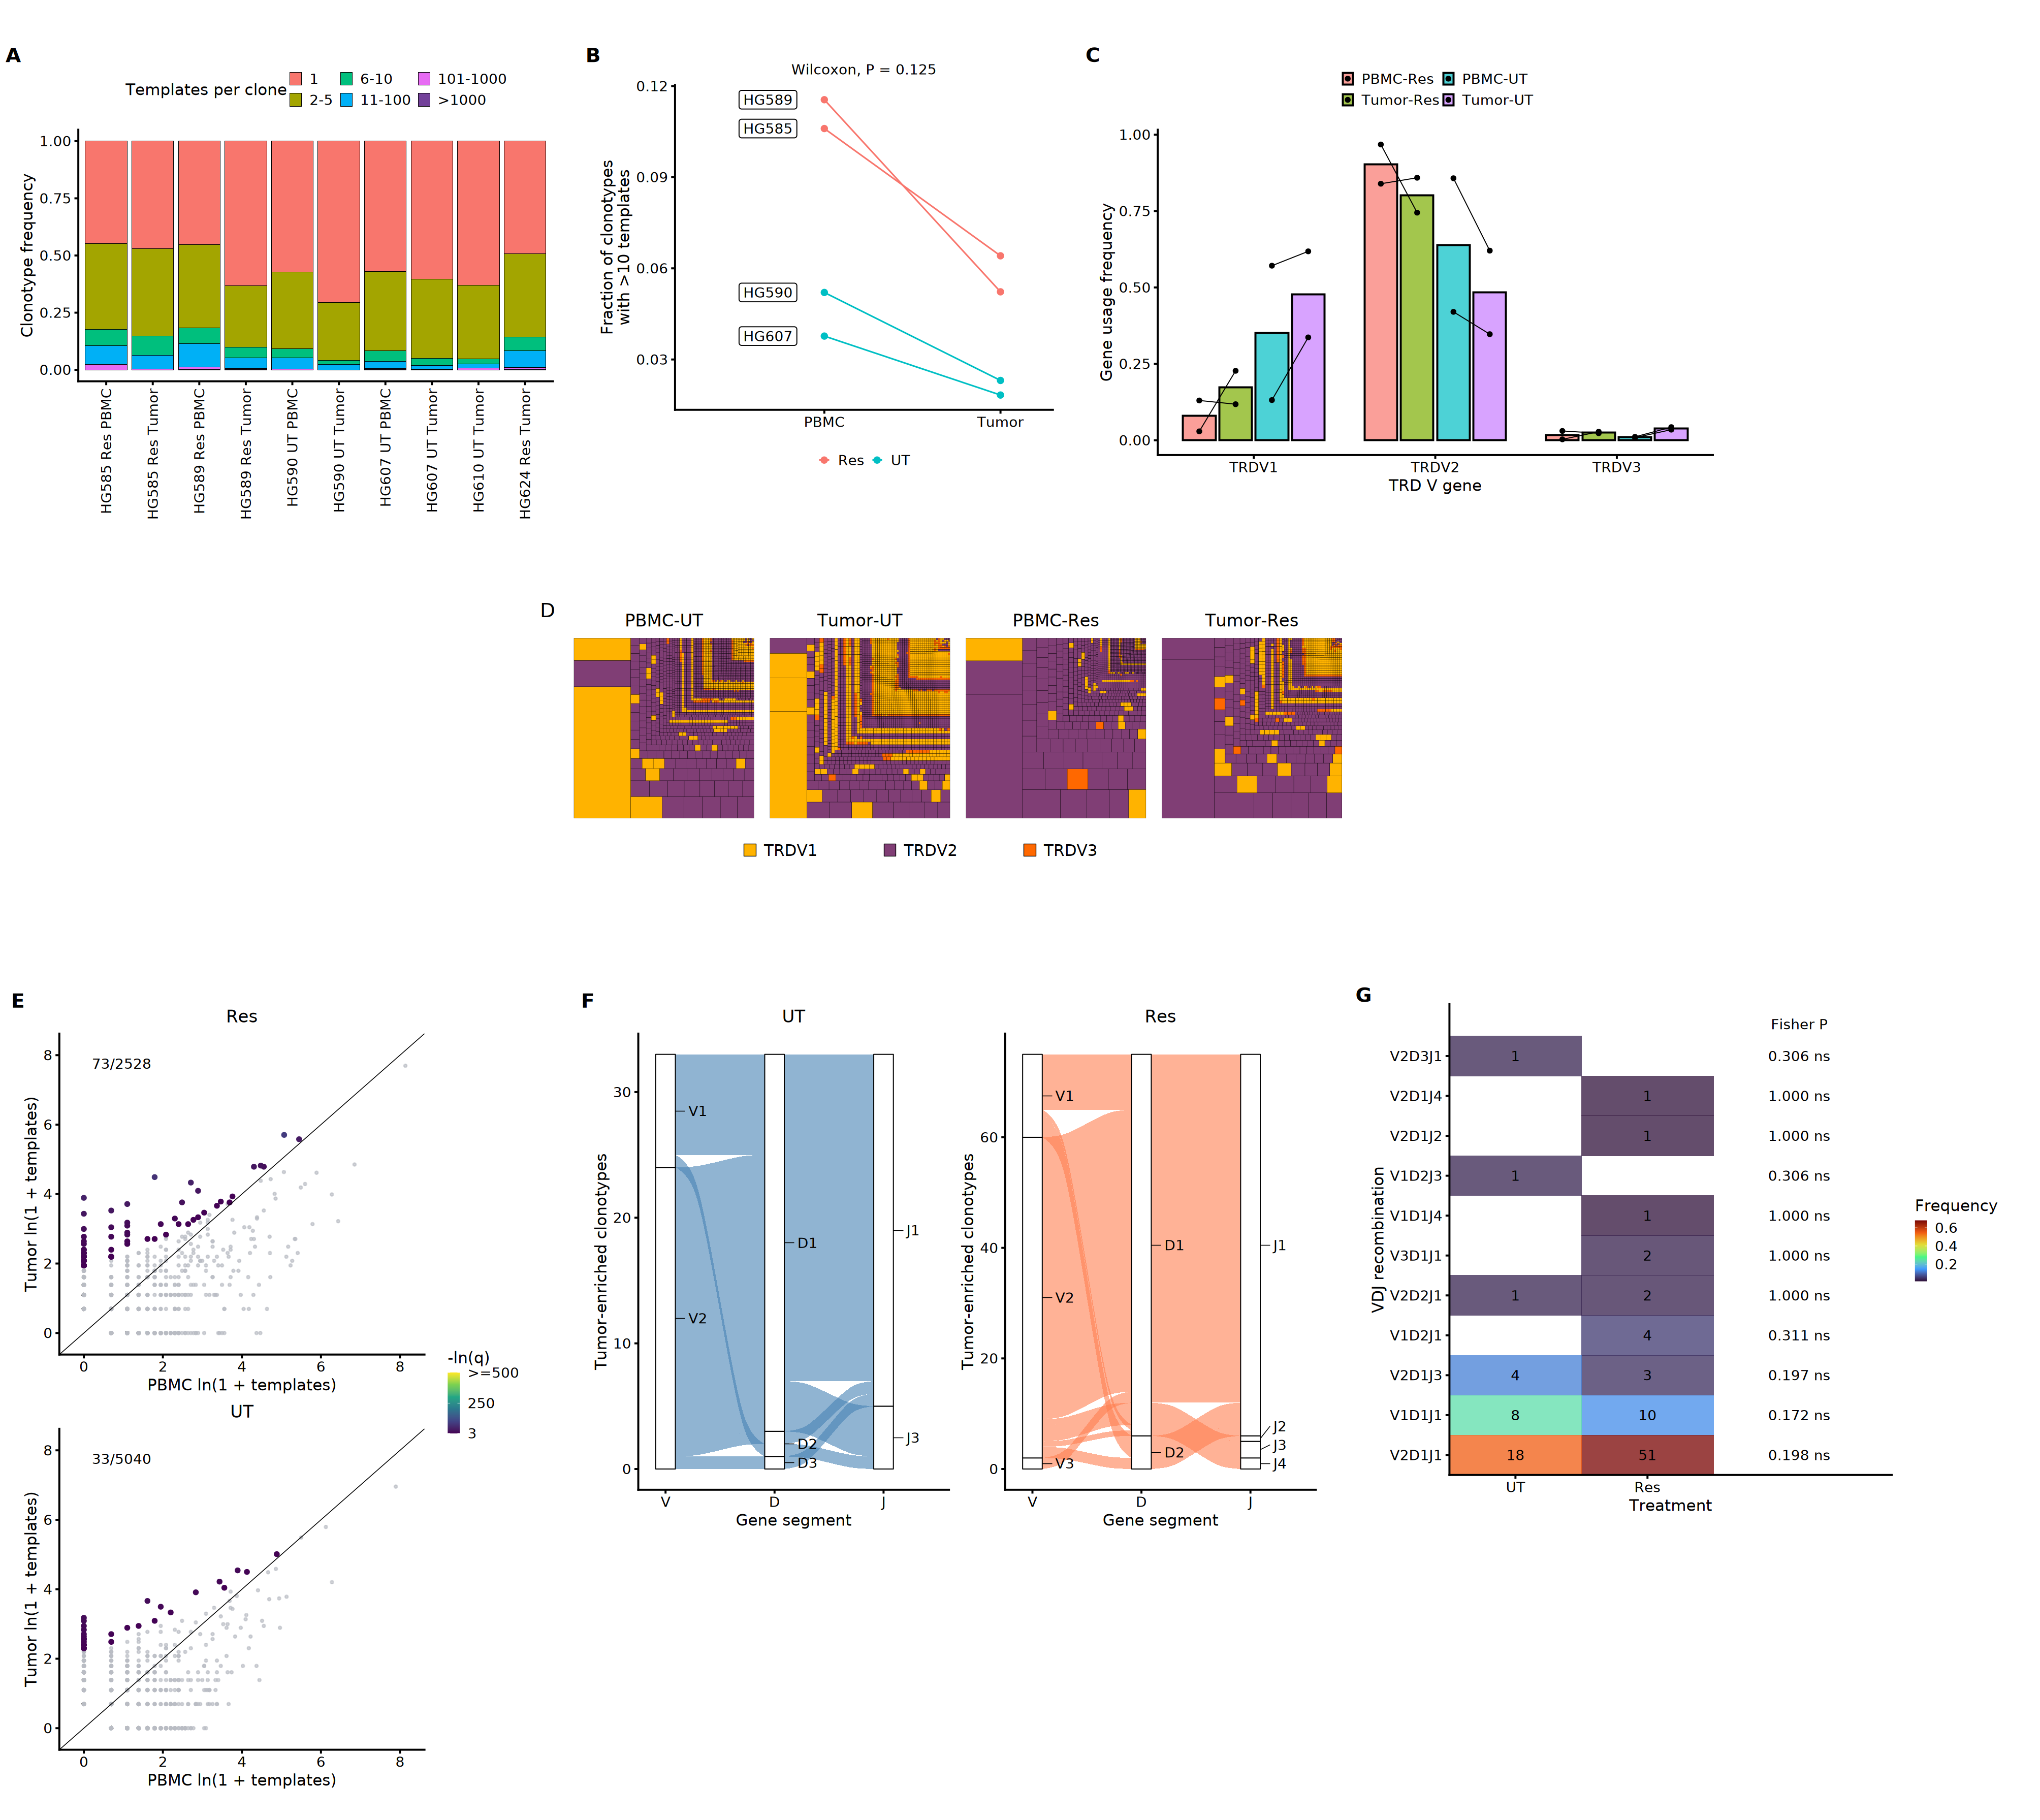

In [10]:
main_positions <- list(A=c(0,650,280,240),B=c(290,670,240,220),C=c(540,660,320,230),
                       D=c(265,475,430,140),E=c(0,10,270,410),F=c(285,140,380,280),G=c(675,150,330,270))
draw_main <- local({ fs <- figures; positions <- main_positions;function(new_page=TRUE) {
    if(new_page) grid.newpage()
    for(letter in names(positions)) {
        r <- positions[[letter]]
        pushViewport(viewport(x=unit(r[1],"mm"),y=unit(r[2],"mm"),width=unit(r[3],"mm"),height=unit(r[4],"mm"),just=c("left","bottom")))
        fs[[paste0("Figure3",letter)]]$draw(new_page=FALSE);popViewport()
    }
}})
emit_figure("Figure3A-G_revised",draw=draw_main,width=1020,height=910,
    caption="Combined main Figure 3A-G, redrawn from the calculation and plotting functions above. Panel-specific methods and legends accompany each individual figure. All figures use productive sequences and exclude uncertain HG610 PBMC; HG606 tumor is excluded for sparsity.")

## S-TCR1 - Individual donor treemaps

Rectangle area is proportional to template count; color identifies TRDV. Two tissue rows share one column per donor. Print templates and unique clonotypes above each 90 x 90 mm plotting panel. Missing PBMC specimens are left unplotted.

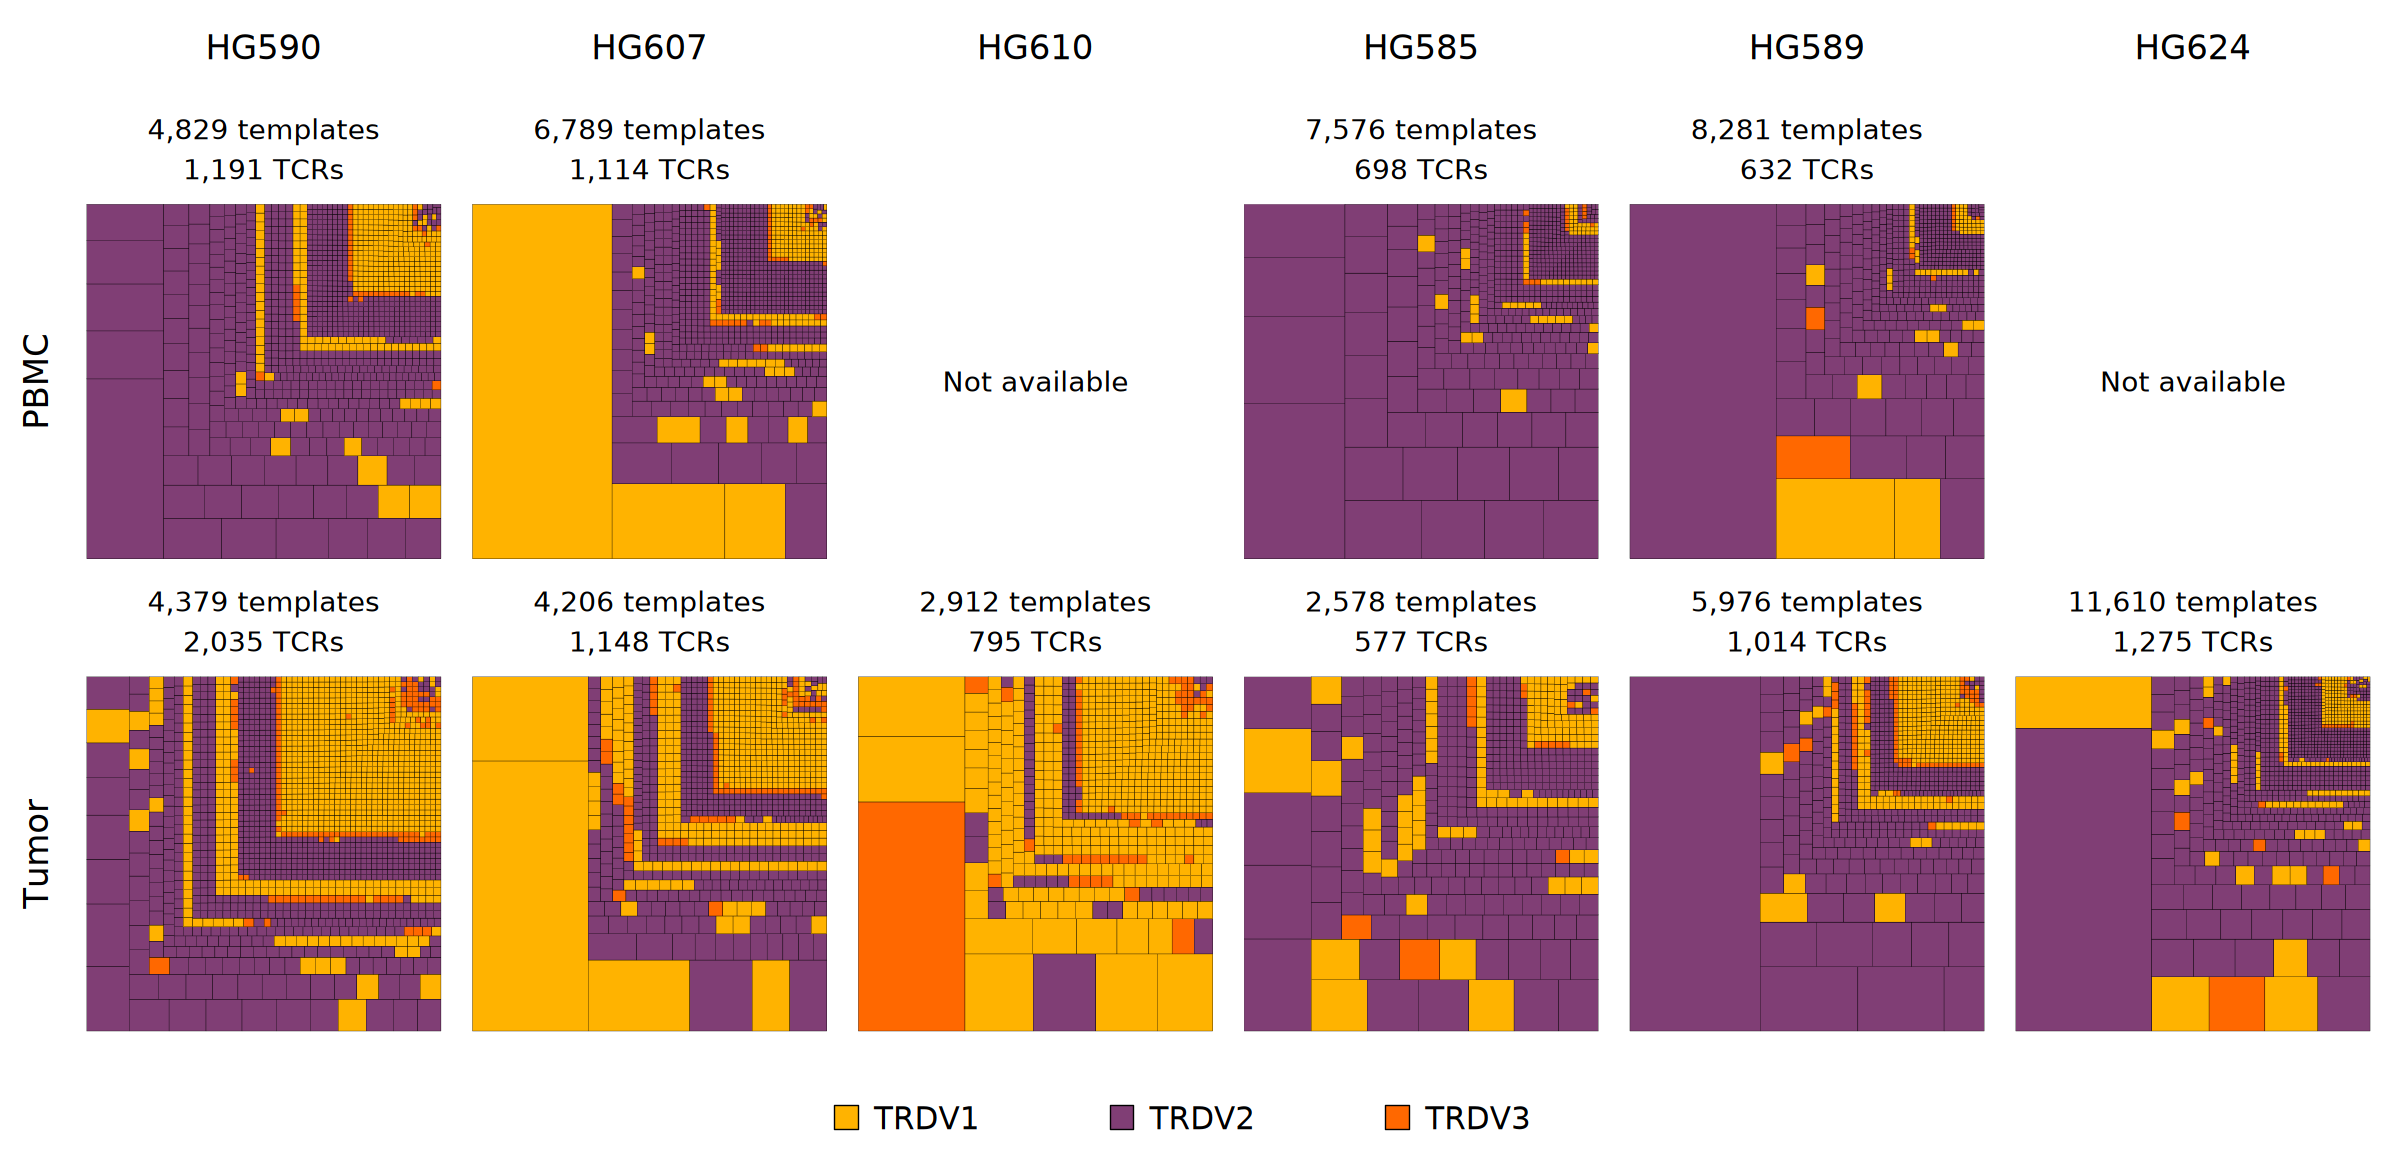

In [11]:
s1_plots <- lapply(specimen_order,function(s) treemap_plot(tables[[s]]));names(s1_plots) <- specimen_order
s1_counts <- filter(qc,included_primary) %>% select(sample,patient,treatment,tissue,retained_productive_TRD_counts,retained_clonotypes)
save_table(s1_counts,"S_TCR1_panel_counts")
draw_S1 <- local({ps <- s1_plots;counts <- s1_counts;function(new_page=TRUE) {
    if(new_page) grid.newpage()
    for(i in seq_along(DONORS)) {
        p <- DONORS[i];x <- 22+(i-1)*98
        grid_text_mm(p,x+45,282,size=24)
        for(tissue in c("PBMC","Tumor")) {
            y <- if(tissue=="PBMC") 152 else 32
            s <- names(ps)[startsWith(names(ps),paste0(p,"_")) & endsWith(names(ps),tissue)]
            if(length(s)) {
                q <- filter(counts,sample==s);place_plot_mm(ps[[s]],x,y,90,90)
                grid_text_mm(paste0(format(q$retained_productive_TRD_counts,big.mark=",",trim=TRUE)," templates\n",
                    format(q$retained_clonotypes,big.mark=",",trim=TRUE)," TCRs"),x+45,y+104,size=20)
            } else grid_text_mm("Not available",x+45,y+45,size=20)
        }
    }
    grid_text_mm("PBMC",9,197,size=24,rot=90);grid_text_mm("Tumor",9,77,size=24,rot=90)
    kelly_legend(215,10)
}})
treemap_audit$S_TCR1 <- data.frame(sample=specimen_order,width_mm=90,height_mm=90)
emit_figure("S-TCR1",draw=draw_S1,width=608,height=294,scope="requested",
    caption="S-TCR1. Individual productive TRD repertoires. Each donor occupies one column, with PBMC above tumor. Template and unique-clonotype totals are printed above each 90 x 90 mm treemap. Area represents template frequency; Kelly colors match Figure 3D. HG610 PBMC is excluded for uncertain identity; HG624 has no PBMC export. HG606 tumor is excluded for sparsity.")

## S-TCR2 - Export depth, productive retention, and clonotype count

Total counts include every exported rearrangement; productive counts require status In; retained TRD additionally passes the original annotation filter. Counts are templates. Unique TCRs count aggregated amino-acid/V/D/J/length clonotypes after both filters. Nested bars show successive count totals.

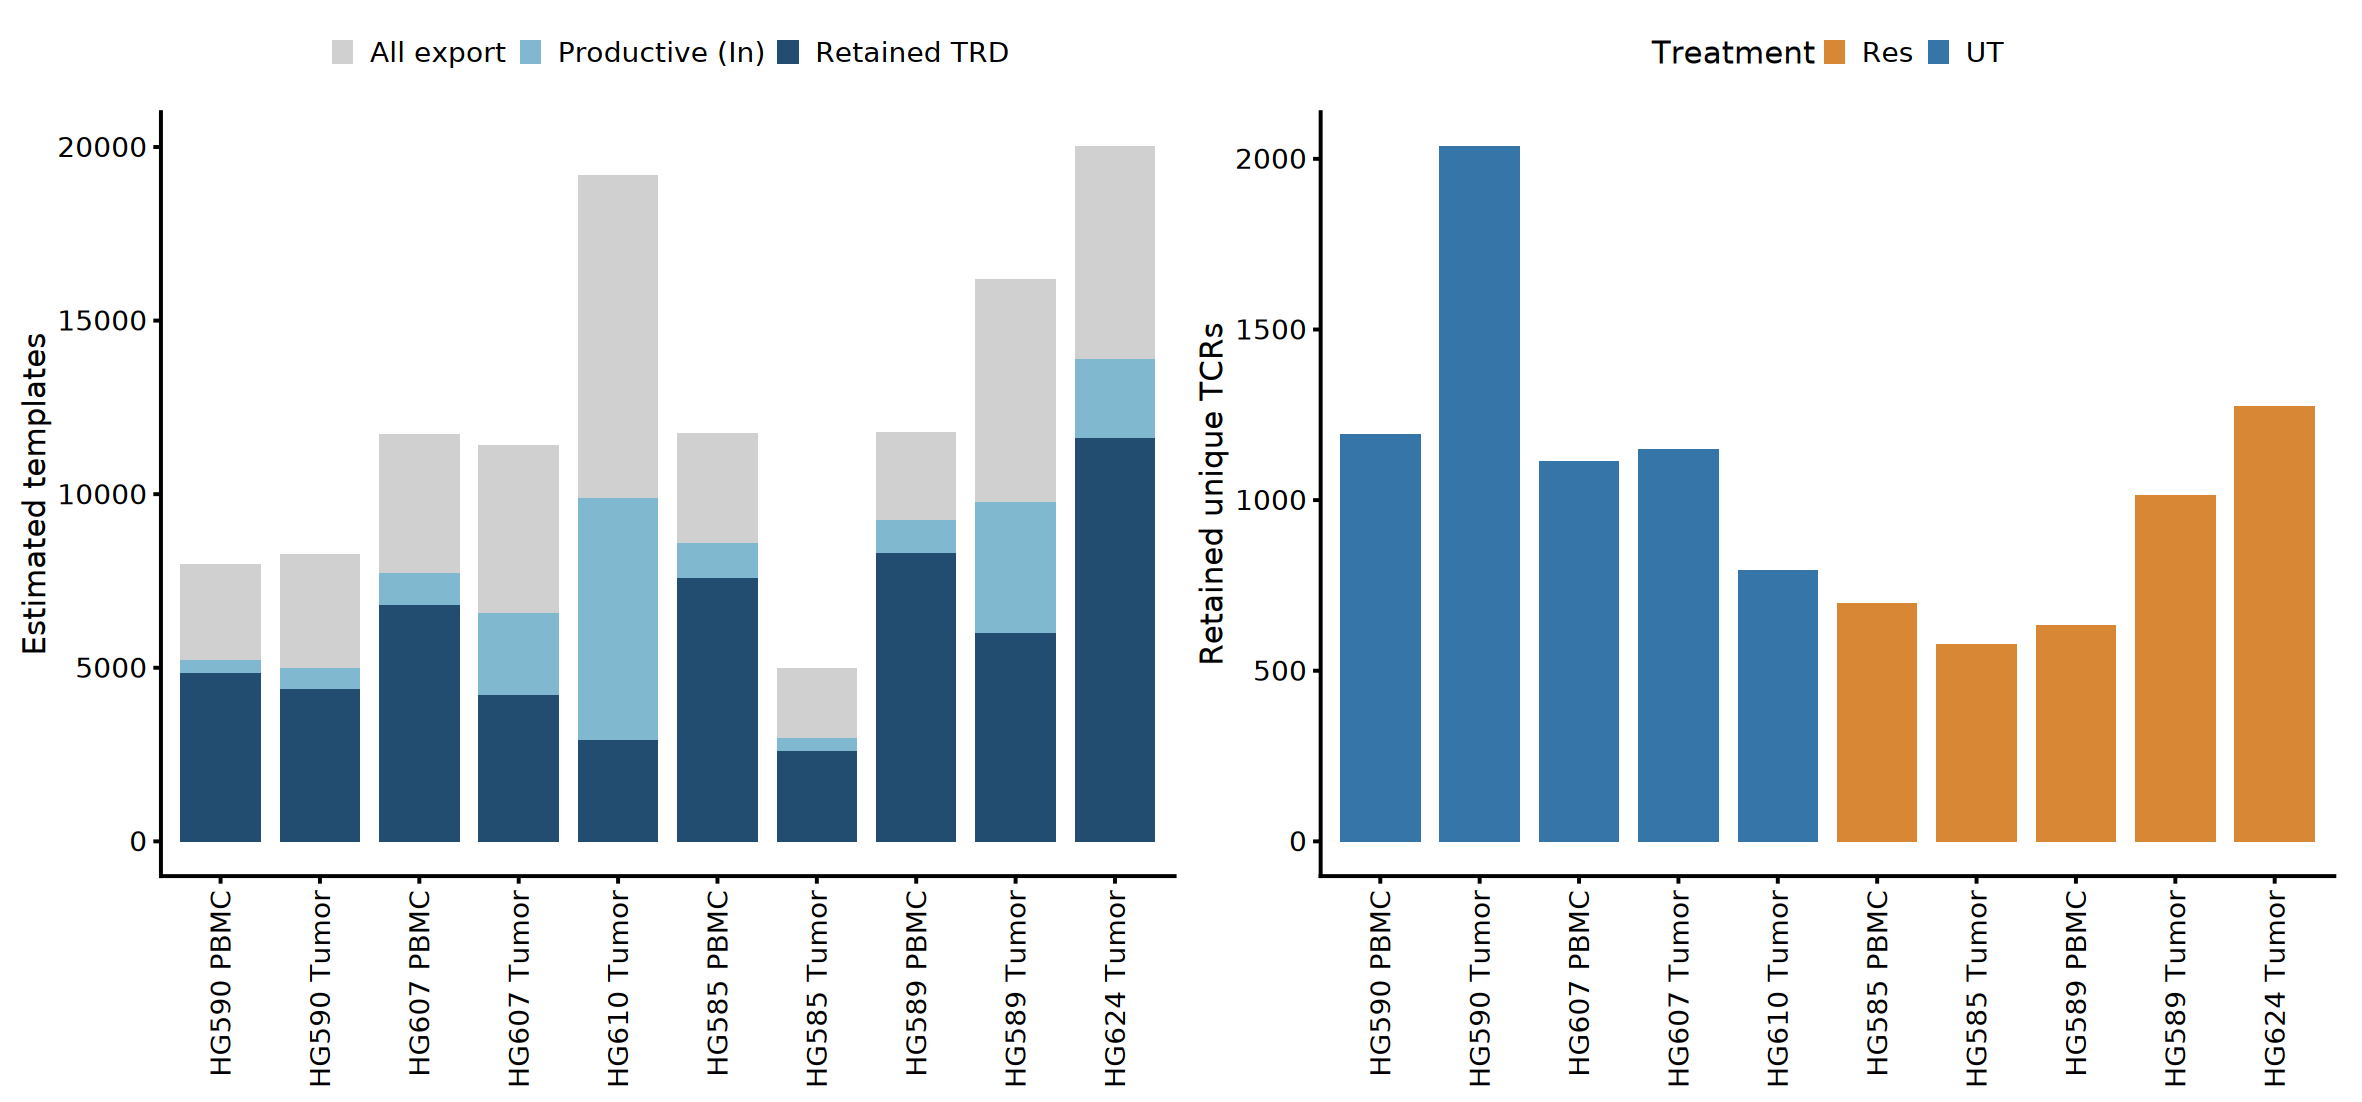

In [12]:
s2 <- qc %>% filter(included_primary) %>% mutate(sample=factor(sample,levels=specimen_order))
s2_long <- s2 %>% select(sample,total_export_counts,productive_export_counts,retained_productive_TRD_counts) %>%
    pivot_longer(-sample,names_to="stage",values_to="templates") %>% mutate(stage=factor(stage,
        levels=c("total_export_counts","productive_export_counts","retained_productive_TRD_counts"),
        labels=c("All export","Productive (In)","Retained TRD")))
s2a <- ggplot(s2_long,aes(sample,templates,fill=stage))+geom_col(position="identity",width=.8)+
    scale_fill_manual(values=c("#D0D0D0","#80B8D0","#234D70"))+scale_x_discrete(labels=sample_labels)+
    labs(x=NULL,y="Estimated templates",fill=NULL)+theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="top")
s2b <- ggplot(s2,aes(sample,retained_clonotypes,fill=treatment))+geom_col(width=.8)+
    scale_fill_manual(values=SUP_COLORS)+scale_x_discrete(labels=sample_labels)+labs(x=NULL,y="Retained unique TCRs",fill="Treatment")+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="top")
emit_figure("S-TCR2",s2a|s2b,width=600,height=280,scope="requested",
    caption="S-TCR2. Export depth and filtering. Overlaid bars show all export templates, productive (sequenceStatus In) templates, and retained productive TRD templates. Retained TRD also has nonempty amino-acid/V/D/J calls and no TCRA V/J annotation. The right panel counts unique retained clonotypes. Raw sequencing-read counts and counting-method versions are absent from these exports.")

## S-TCR3 - Sampling-depth sensitivity

Draw templates without replacement using a multivariate hypergeometric distribution at the minimum retained specimen depth. Equal depth removes differences in total sampling effort; the same sampling fraction would retain unequal depths. This checks depth sensitivity, not biological equivalence. Repeat 1,000 times with a fixed R seed. Richness counts detected clones; Simpson dominance is sum(frequency squared); Shannon entropy is -sum(frequency log frequency). TRDV use is template weighted. Also calculate richness curves at five fixed depths (200 draws per depth).

In [13]:
sample_counts <- function(counts,depth,n_draws) {
    stopifnot(depth<=sum(counts),all(counts>=0),depth>0)
    ans <- matrix(0,nrow=n_draws,ncol=length(counts));remaining <- rep(depth,n_draws);available <- sum(counts)
    for(j in seq_len(length(counts)-1L)) {
        ans[,j] <- rhyper(n_draws,m=counts[j],n=available-counts[j],k=remaining)
        remaining <- remaining-ans[,j];available <- available-counts[j]
    }
    ans[,length(counts)] <- remaining
    stopifnot(all(rowSums(ans)==depth),all(sweep(ans,2,counts,`<=`)))
    ans
}
draw_metrics <- function(ds,genes) {
    freq <- ds/rowSums(ds);positive <- ds>0
    entropy_terms <- matrix(0,nrow(ds),ncol(ds));entropy_terms[positive] <- freq[positive]*log(freq[positive])
    data.frame(retained_counts=rowSums(ds),richness=rowSums(positive),simpson_dominance=rowSums(freq^2),
        shannon_entropy=-rowSums(entropy_terms),fraction_clones_gt10=rowSums(ds>10)/rowSums(positive),
        TRDV1=rowSums(freq[,genes==GENES[1],drop=FALSE]),TRDV2=rowSums(freq[,genes==GENES[2],drop=FALSE]),
        TRDV3=rowSums(freq[,genes==GENES[3],drop=FALSE]))
}
depth <- min(observed$retained_counts);stopifnot(depth==2578)
ds_arrays <- list();draw_list <- list();curves <- list();rng_checks <- list()
for(s in samples) {
    x <- tables[[s]];meta <- x[1,c("sample","patient","treatment","tissue")]
    ds <- sample_counts(x$count,depth,REPS);ds_arrays[[s]] <- ds
    draws_s <- draw_metrics(ds,x$vGeneName)
    draw_list[[s]] <- cbind(meta[rep(1,REPS),],iteration=seq_len(REPS)-1L,depth=depth,draws_s)
    for(dep in c(500,1000,1500,2000,depth)) {
        richness <- rowSums(sample_counts(x$count,dep,200)>0)
        curves[[length(curves)+1L]] <- cbind(meta,depth=dep,mean_richness=mean(richness),
            q025=unname(quantile(richness,.025)),q975=unname(quantile(richness,.975)))
    }
    for(g in seq_along(GENES)) {
        p <- sum(x$count[x$vGeneName==GENES[g]])/sum(x$count)
        se_mean <- sqrt(p*(1-p)*(sum(x$count)-depth)/(depth*(sum(x$count)-1))/REPS)
        delta <- abs(mean(draws_s[[GSHORT[g]]])-p)
        rng_checks[[length(rng_checks)+1L]] <- data.frame(sample=s,gene=GSHORT[g],mean_error=delta,
            standard_error_of_mean=se_mean,passes_six_SE=delta<=6*se_mean+1e-12)
    }
    cat("Sampled",s,"at",depth,"templates\n")
}
draws <- bind_rows(draw_list);rarefaction <- bind_rows(curves);rng_checks <- bind_rows(rng_checks)
stopifnot(all(rng_checks$passes_six_SE))
metric_names <- c("richness","simpson_dominance","shannon_entropy","fraction_clones_gt10",GSHORT)
ds_summary <- draws %>% pivot_longer(all_of(metric_names),names_to="metric",values_to="value") %>%
    group_by(sample,patient,treatment,tissue,metric) %>% summarise(depth=first(depth),iterations=n(),
        median=median(value),q025=quantile(value,.025),q975=quantile(value,.975),.groups="drop") %>%
    left_join(observed %>% select(sample,all_of(metric_names)) %>% pivot_longer(-sample,names_to="metric",values_to="observed"),by=c("sample","metric"))
robustness <- ds_summary %>% group_by(metric) %>% summarise(spearman_observed_vs_rarefied_medians=safe_cor(observed,median),.groups="drop")
save_table(draws,"downsampling_iterations");save_table(rarefaction,"rarefaction_curves")
save_table(ds_summary,"downsampling_summary");save_table(robustness,"sampling_robustness")
save_table(rng_checks,"R_sampling_distribution_checks")

Sampled HG585_Res_PBMC at 2578 templates
Sampled HG585_Res_Tumor at 2578 templates
Sampled HG589_Res_PBMC at 2578 templates
Sampled HG589_Res_Tumor at 2578 templates
Sampled HG590_UT_PBMC at 2578 templates
Sampled HG590_UT_Tumor at 2578 templates
Sampled HG607_UT_PBMC at 2578 templates
Sampled HG607_UT_Tumor at 2578 templates
Sampled HG610_UT_Tumor at 2578 templates
Sampled HG624_Res_Tumor at 2578 templates


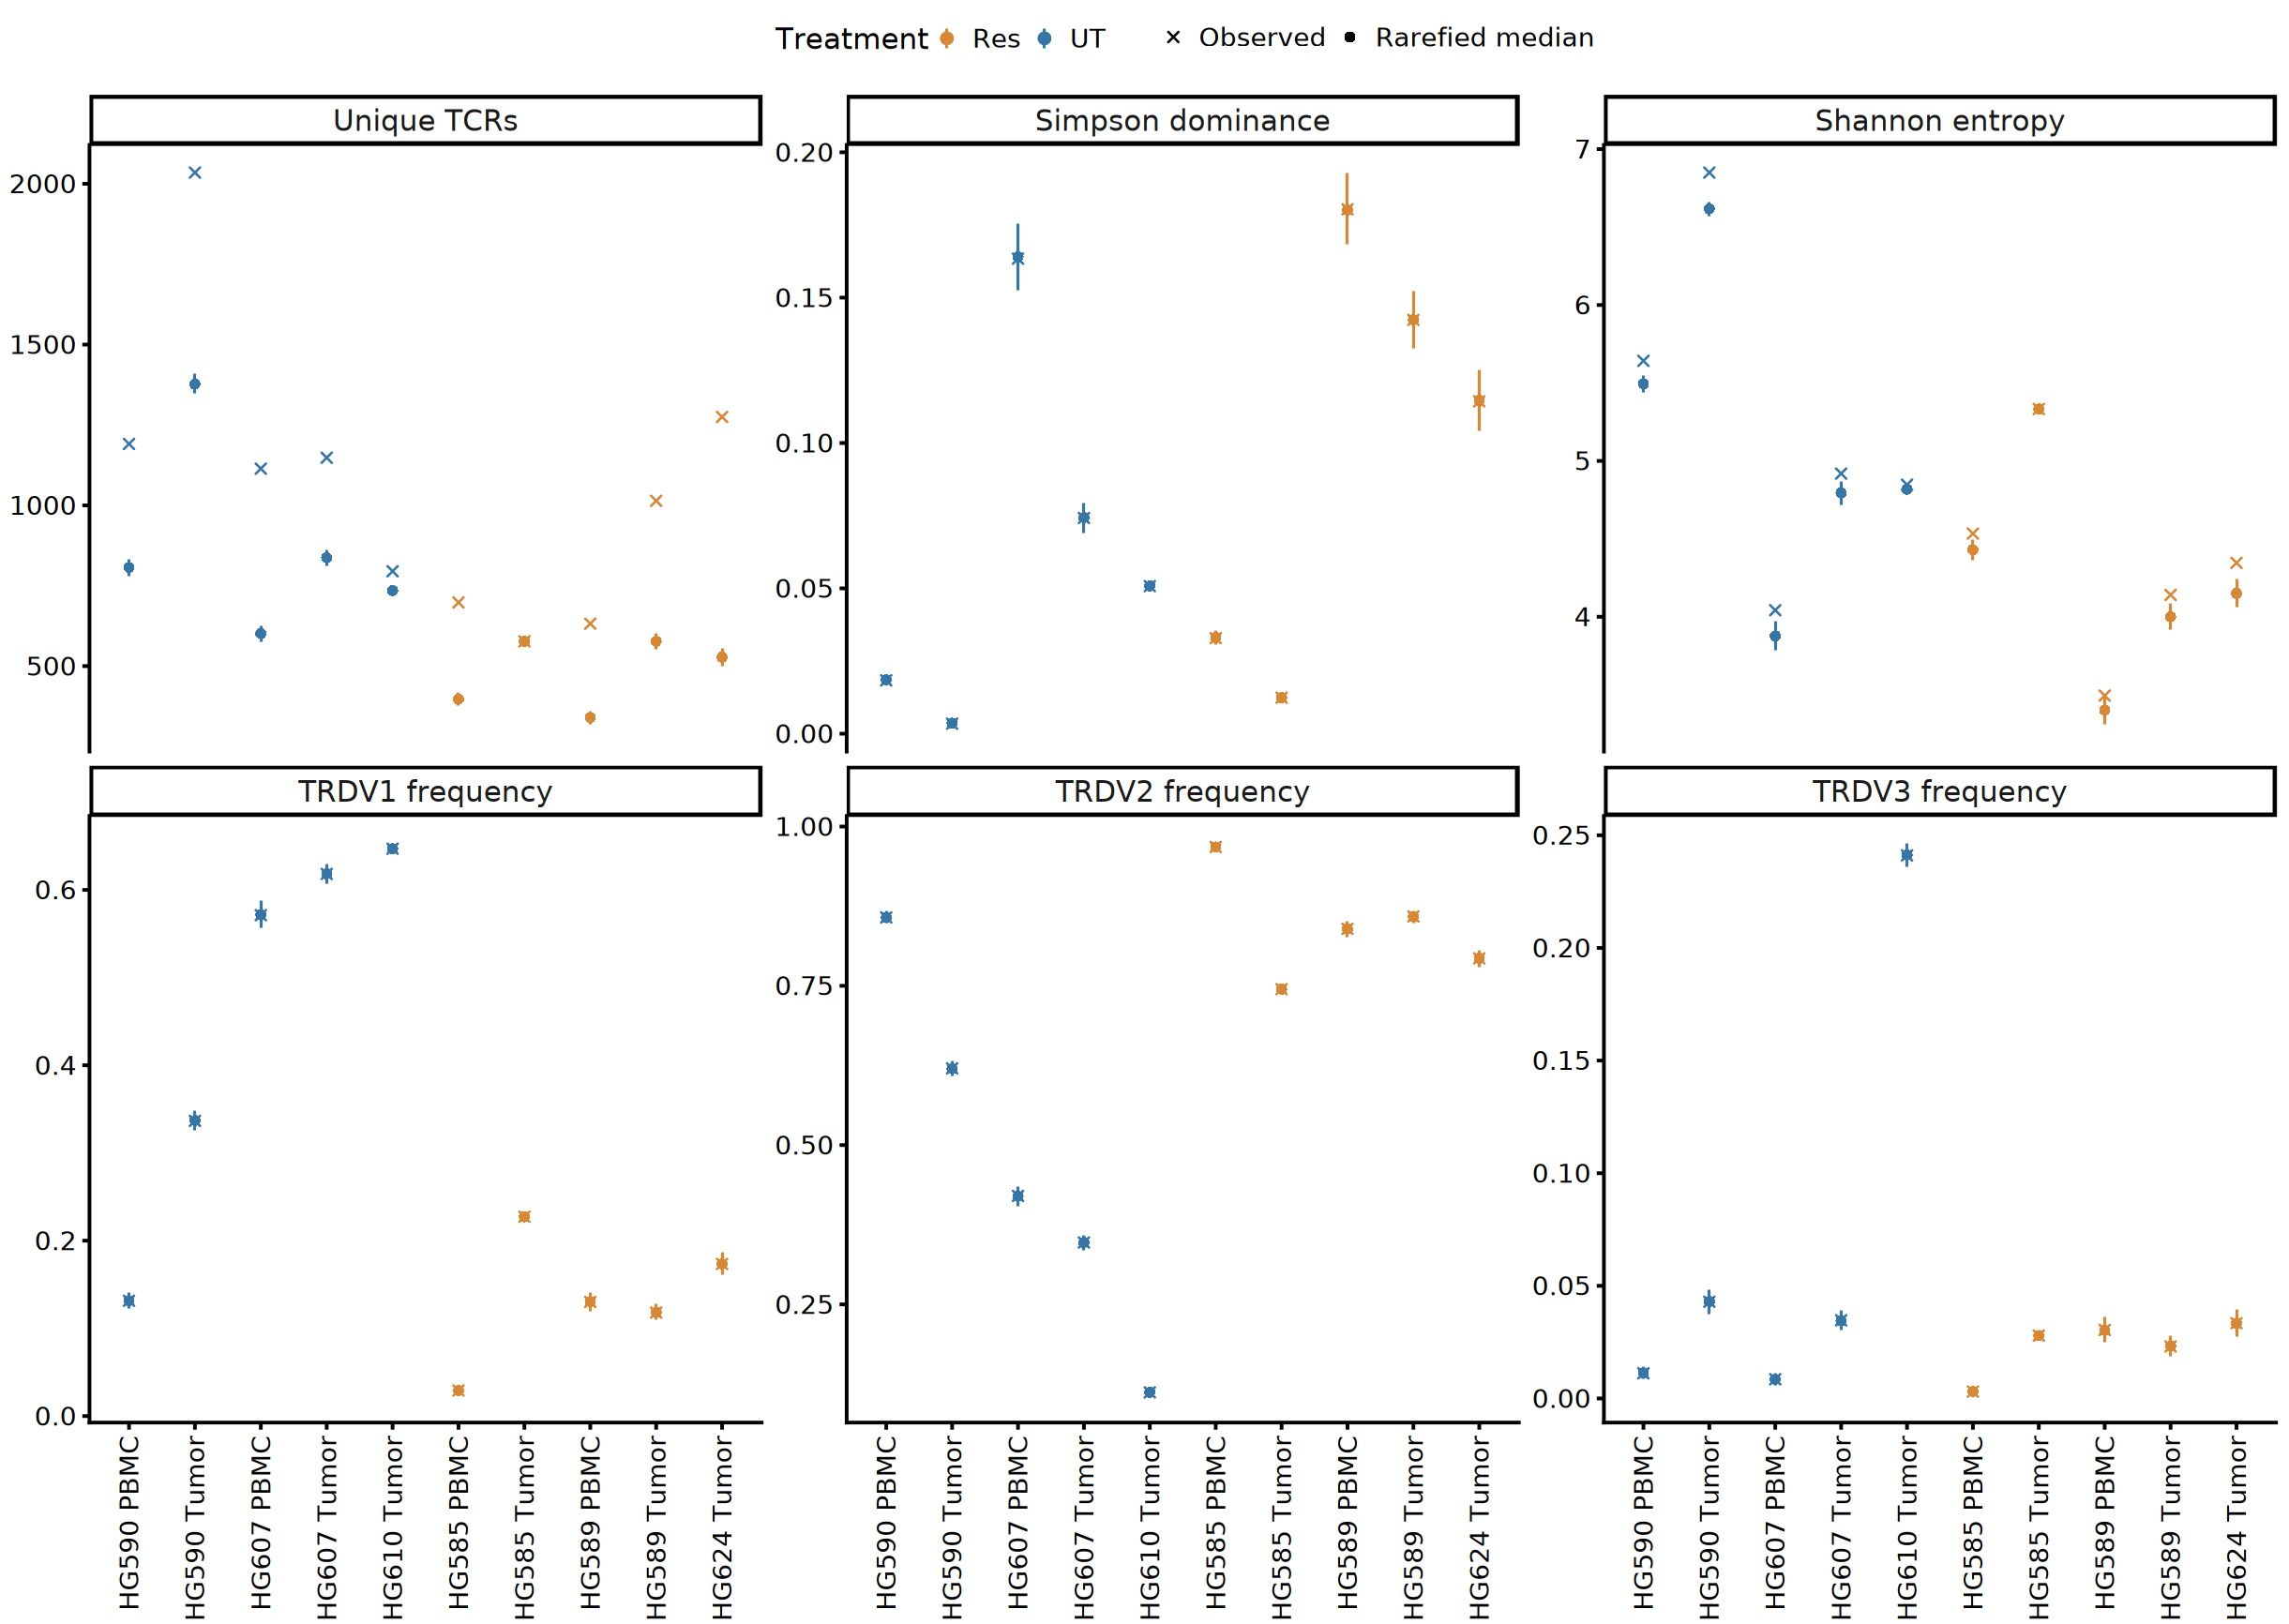

In [14]:
s3_metrics <- c("richness","simpson_dominance","shannon_entropy","TRDV1","TRDV2","TRDV3")
metric_labels <- c(richness="Unique TCRs",simpson_dominance="Simpson dominance",shannon_entropy="Shannon entropy",
                   fraction_clones_gt10="Fraction with >10 templates",TRDV1="TRDV1 frequency",TRDV2="TRDV2 frequency",TRDV3="TRDV3 frequency")
s3 <- ds_summary %>% filter(metric %in% s3_metrics) %>% mutate(sample=factor(sample,levels=specimen_order),metric=factor(metric,levels=s3_metrics))
plot_S3 <- ggplot(s3,aes(sample,median,colour=treatment))+geom_linerange(aes(ymin=q025,ymax=q975),linewidth=.8)+
    geom_point(aes(shape="Rarefied median"),size=3)+geom_point(aes(y=observed,shape="Observed"),size=3)+
    scale_shape_manual(values=c("Rarefied median"=16,Observed=4))+scale_colour_manual(values=SUP_COLORS)+
    scale_x_discrete(labels=sample_labels)+facet_wrap(~metric,ncol=3,scales="free_y",labeller=as_labeller(metric_labels))+
    labs(x=NULL,y=NULL,colour="Treatment",shape=NULL)+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="top")
emit_figure("S-TCR3",plot_S3,width=620,height=440,scope="requested",
    caption="S-TCR3. Sampling-depth sensitivity at 2,578 retained templates per specimen. Crosses indicate observed values; circles and intervals are rarefied medians and 2.5th-97.5th percentiles from 1,000 draws without replacement. Intervals quantify sampling variation rather than population confidence intervals. R and Python use different seeded random streams. Five-depth richness curves and all iterations accompany the figure as source data.")

## S-TCR4 - Within-patient PBMC-tumor overlap and enrichment

Within each matched patient, test clone counts against remaining templates in the two specimens, adjusting Fisher P values by BH within patient. Enrichment direction uses specimen-normalized frequency. Calculate Spearman correlations on the clone union and shared clones separately; Morisita-Horn is twice the frequency cross-product divided by summed squared frequencies. Jaccard is shared/union clonotypes. Repeat overlap calculations on the equal-depth samples. These patient-wise denominators differ intentionally from main Figure 3E's treatment-group totals.

In [15]:
paired_frames <- list();correlation_rows <- list();corr_iterations <- list()
for(patient in PAIRS) {
    ss <- samples[startsWith(samples,paste0(patient,"_"))];a <- ss[endsWith(ss,"PBMC")];b <- ss[endsWith(ss,"Tumor")]
    u <- pair_unions[[patient]] %>% mutate(PBMC_frequency=count_PBMC/sum(count_PBMC),Tumor_frequency=count_Tumor/sum(count_Tumor),
        p_fisher=clone_fisher(count_PBMC,count_Tumor),q_BH_within_patient=p.adjust(p_fisher,"BH"),
        enrichment=ifelse(q_BH_within_patient<.05,ifelse(Tumor_frequency>PBMC_frequency,"Tumor","PBMC"),"not significant"))
    paired_frames[[patient]] <- u
    both <- u$count_PBMC>0 & u$count_Tumor>0;fa <- u$PBMC_frequency;fb <- u$Tumor_frequency
    correlation_rows[[patient]] <- data.frame(patient=patient,treatment=u$treatment[1],union_clonotypes=nrow(u),
        shared_clonotypes=sum(both),PBMC_only=sum(u$count_PBMC>0 & u$count_Tumor==0),Tumor_only=sum(u$count_Tumor>0 & u$count_PBMC==0),
        spearman_union=safe_cor(fa,fb),spearman_shared=safe_cor(fa[both],fb[both]),
        Morisita_Horn=2*sum(fa*fb)/(sum(fa^2)+sum(fb^2)),jaccard=mean(both),
        tumor_enriched_clonotypes=sum(u$enrichment=="Tumor"),tumor_enriched_fraction_of_union=mean(u$enrichment=="Tumor"))
    ia <- match(tables[[a]]$clone_key,u$clone_key);ib <- match(tables[[b]]$clone_key,u$clone_key)
    corr_iterations[[patient]] <- bind_rows(lapply(seq_len(REPS),function(i) {
        da <- db <- numeric(nrow(u));da[ia] <- ds_arrays[[a]][i,];db[ib] <- ds_arrays[[b]][i,]
        seen <- da+db>0;shared <- da>0 & db>0
        data.frame(patient=patient,iteration=i-1L,depth=depth,spearman_union=safe_cor(da[seen],db[seen]),
            spearman_shared=if(sum(shared)>2) safe_cor(da[shared],db[shared]) else NA_real_,shared_clonotypes=sum(shared),
            Morisita_Horn=2*sum(da*db)/(sum(da^2)+sum(db^2)))
    }))
    cat("Paired analysis",patient,"\n")
}
patient_correlations <- bind_rows(correlation_rows);paired_tests <- bind_rows(paired_frames);ci <- bind_rows(corr_iterations)
cs <- ci %>% group_by(patient) %>% summarise(across(c(spearman_union,spearman_shared,Morisita_Horn),
    list(median=~median(.x,na.rm=TRUE),q025=~quantile(.x,.025,na.rm=TRUE),q975=~quantile(.x,.975,na.rm=TRUE)),.names="{.col}_{.fn}"),.groups="drop")
save_table(patient_correlations,"patient_correlations");save_table(paired_tests,"paired_clone_tests")
save_table(ci,"correlation_downsampling_iterations");save_table(cs,"correlation_downsampling_summary")

Paired analysis HG585 
Paired analysis HG589 
Paired analysis HG590 
Paired analysis HG607 


patient,treatment,union_clonotypes,shared_clonotypes,PBMC_only,Tumor_only,spearman_union,spearman_shared,Morisita_Horn,jaccard,tumor_enriched_clonotypes,tumor_enriched_fraction_of_union
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
HG585,Res,1103,172,526,405,-0.2824936,0.4816638,0.6144970,0.15593835,81,0.073436083
HG589,Res,1425,221,411,793,-0.2262342,0.5708498,0.9676980,0.15508772,17,0.011929825
HG590,UT,2970,256,935,1779,-0.5236437,0.4041268,0.4204863,0.08619529,17,0.005723906
HG607,UT,2070,192,922,956,-0.5483002,0.3505084,0.9025344,0.09275362,14,0.006763285


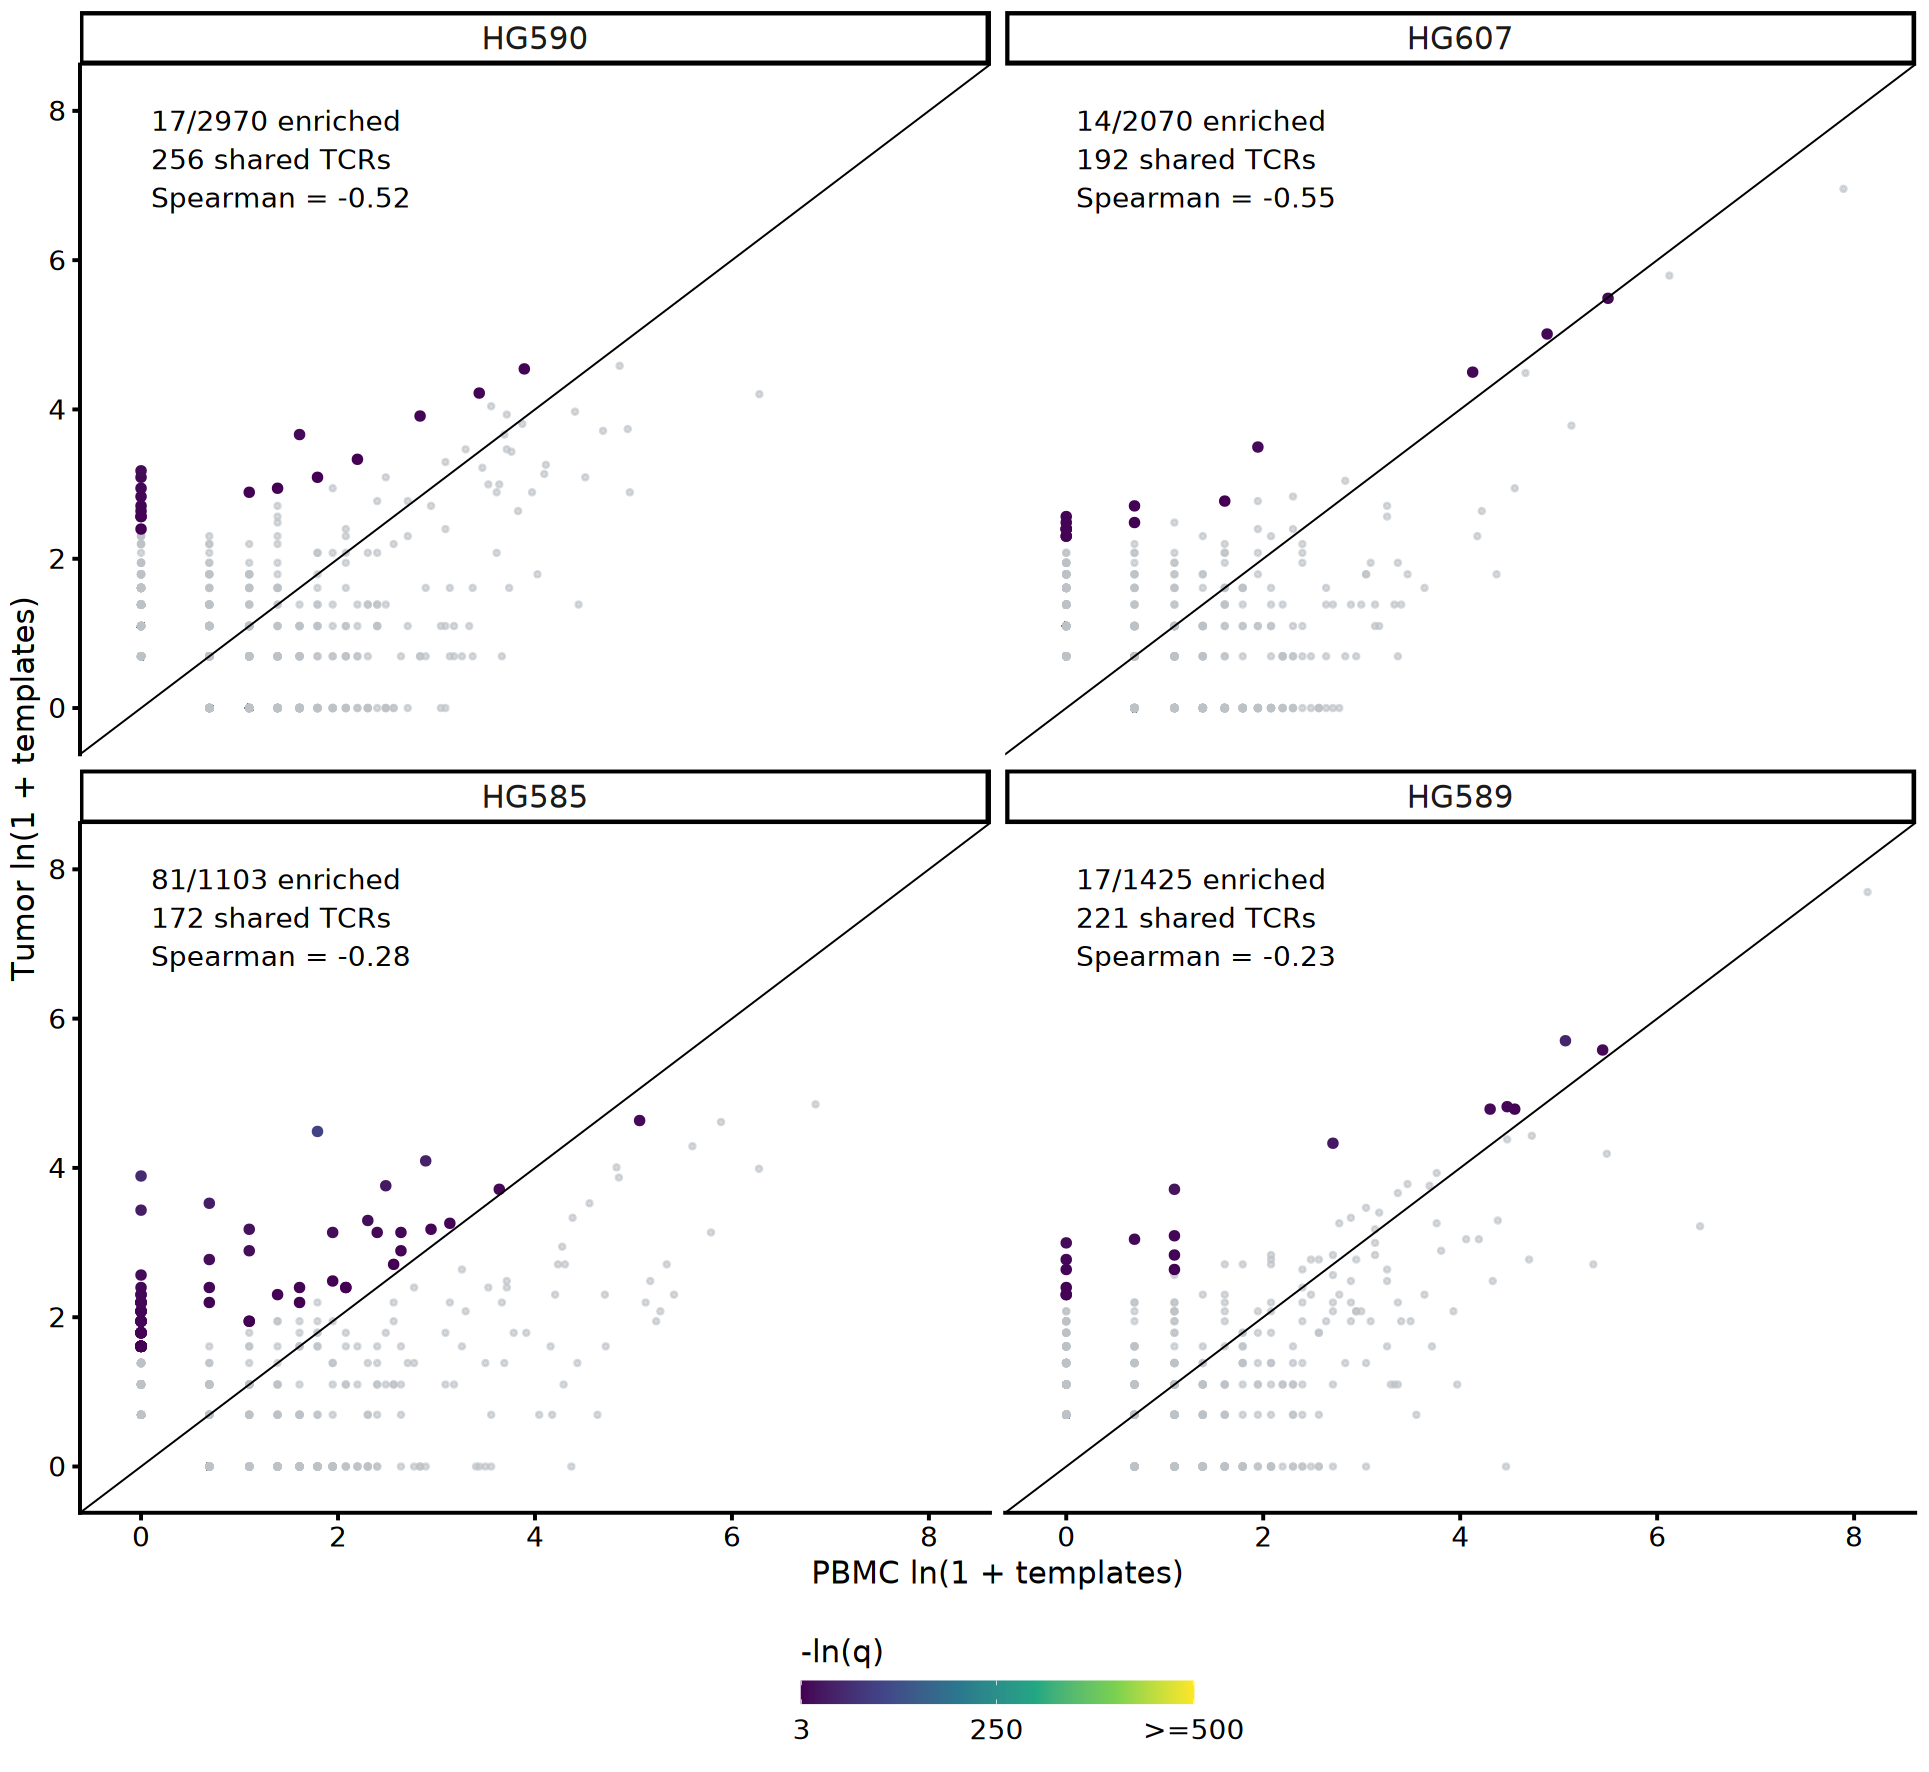

In [16]:
s4 <- paired_tests %>% mutate(patient=factor(patient,levels=c("HG590","HG607","HG585","HG589")))
s4_sig <- filter(s4,enrichment=="Tumor")
s4_labels <- patient_correlations %>% mutate(patient=factor(patient,levels=levels(s4$patient)),label=paste0(tumor_enriched_clonotypes,"/",union_clonotypes,
    " enriched\n",shared_clonotypes," shared TCRs\nSpearman = ",sprintf("%.2f",spearman_union)))
plot_S4 <- ggplot(s4,aes(log1p(count_PBMC),log1p(count_Tumor)))+geom_point(colour="#BDC2C7",size=1,alpha=.6)+
    geom_point(data=s4_sig,aes(colour=pmin(-log(pmax(q_BH_within_patient,.Machine$double.xmin)),500)),size=2)+
    geom_abline(linewidth=.5)+geom_text(data=s4_labels,aes(x=.1,y=8,label=label),inherit.aes=FALSE,
        hjust=0,vjust=1,size=20/.pt,lineheight=1.15)+facet_wrap(~patient,ncol=2)+coord_cartesian(xlim=c(-.2,8.2),ylim=c(-.2,8.2))+
    scale_colour_viridis_c(name="-ln(q)",limits=c(-log(.05),500),breaks=c(-log(.05),250,500),labels=c("3","250",">=500"))+
    labs(x="PBMC ln(1 + templates)",y="Tumor ln(1 + templates)")+theme(legend.position="bottom")+
    guides(colour=guide_colourbar(barwidth=unit(100,"mm"),barheight=unit(6,"mm"),title.position="top"))
emit_figure("S-TCR4",plot_S4,width=490,height=450,scope="requested",
    caption="S-TCR4. Patient-wise clone enrichment for the four confirmed PBMC-tumor pairs. Colored clones have two-sided Fisher q<0.05 after BH within patient and higher tumor frequency. Labels give tumor-enriched/union clonotypes, shared-clone counts, and union Spearman correlation. HG610 is not paired. Main Figure 3E uses treatment-group totals; these panels use each patient's specimen totals. Equal-depth overlap summaries are included as source data.")
patient_correlations

## S-TCR5 - Optional expansion summary

Reuse the count-bin and >10-template fraction calculations from raw data in Figures 3A/B. Display all included specimens alongside the four paired donors. This optional summary was not directly requested by the reviewer and does not add a new test.

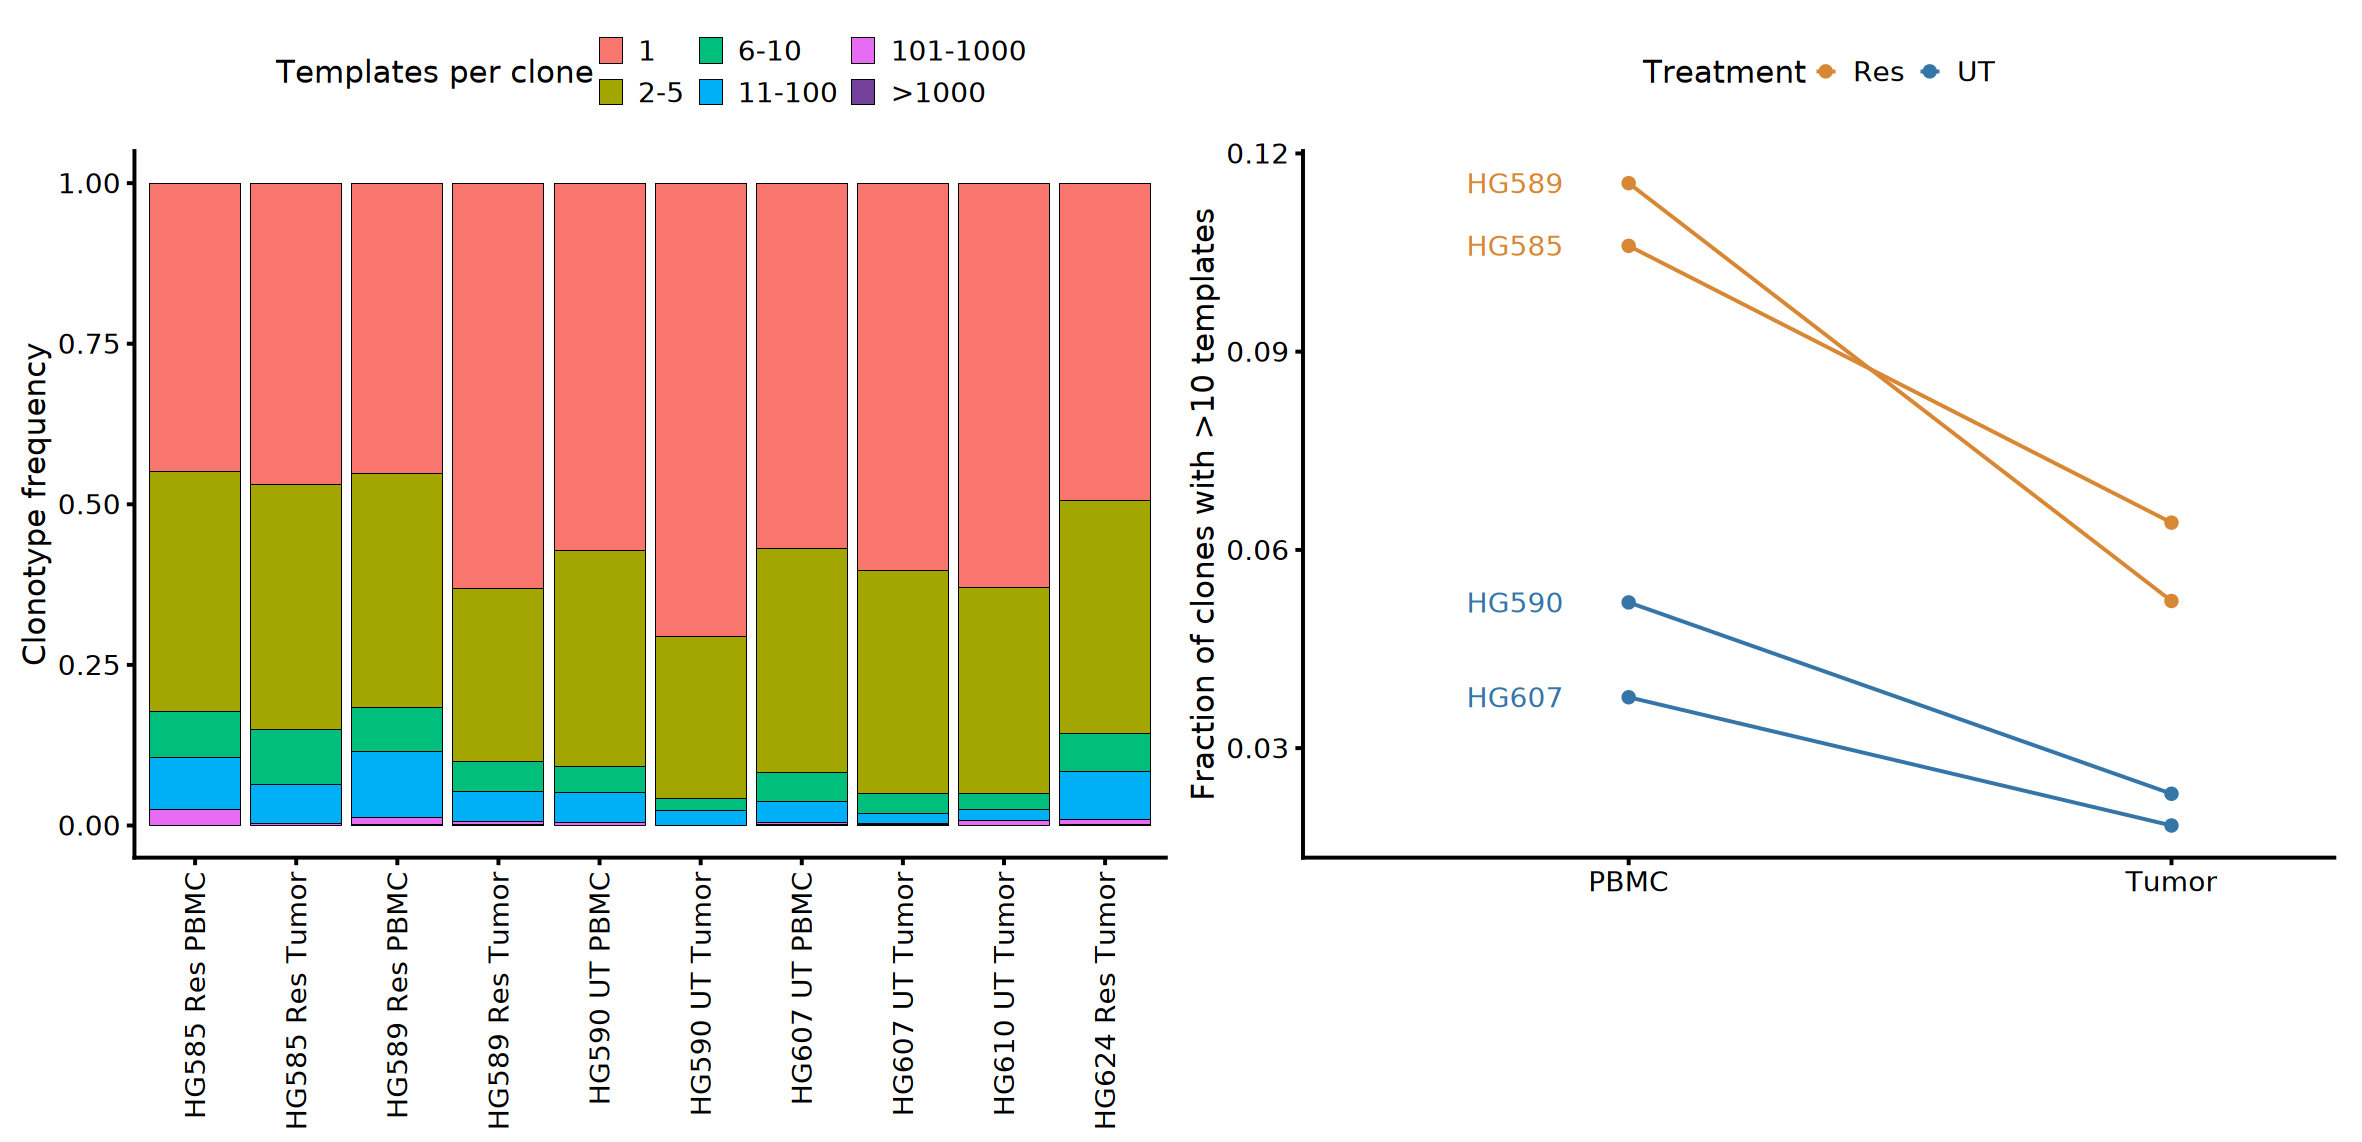

In [17]:
s5a <- plot_A+labs(tag=NULL)+theme(legend.position="top")
s5b <- ggplot(B,aes(factor(tissue,levels=c("PBMC","Tumor")),fraction_clones_gt10,group=patient,colour=treatment))+
    geom_line(linewidth=1)+geom_point(size=3)+geom_text(data=filter(B,tissue=="PBMC"),aes(label=patient),
        hjust=1,nudge_x=-.12,size=20/.pt,show.legend=FALSE)+
    scale_colour_manual(values=SUP_COLORS)+scale_x_discrete(expand=expansion(add=c(.6,.3)))+
    labs(x=NULL,y="Fraction of clones with >10 templates",colour="Treatment")+theme(legend.position="top")
emit_figure("S-TCR5",s5a|s5b,width=600,height=290,scope="optional",
    caption="S-TCR5 (optional). Clonotype abundance-bin fractions for all ten included specimens and >10-template fractions in four paired patients. This descriptive summary uses the same definitions as Figure 3A/B and was not explicitly requested by the reviewer.")

## S-TCR6 - Optional variable-gene and patient-level comparisons

TRDV fractions divide each gene's templates by all retained templates. For paired tissue differences, enumerate every sign flip of patient differences. For treatment comparisons, enumerate every patient-label assignment of the observed group sizes; use absolute mean differences for two-sided exact P values. Apply BH within each comparison family. Report paired-four and all-six tumor analyses separately, and leave-one-patient-out mean effects. These exploratory V-gene analyses are separate from the reviewer's constant-gene question.

In [18]:
statistics_rows <- list()
add_stat <- function(comparison,metric,a,b=NULL,paired_test=FALSE) {
    statistics_rows[[length(statistics_rows)+1L]] <<- data.frame(comparison=comparison,metric=metric,n_1=length(a),
        n_2=if(paired_test) length(a) else length(b),mean_difference=if(paired_test) mean(a) else mean(a)-mean(b),
        p_exact=if(paired_test) exact_paired(a) else exact_group(a,b),
        test=if(paired_test) "two-sided exact sign-flip of paired mean differences" else "two-sided exact permutation of patient labels")
}
for(m in metric_names) {
    w <- observed %>% filter(patient %in% PAIRS) %>% select(patient,tissue,all_of(m)) %>% pivot_wider(names_from=tissue,values_from=all_of(m))
    add_stat("Tumor minus PBMC paired",m,w$Tumor-w$PBMC,paired_test=TRUE)
    for(t in c("PBMC","Tumor")) for(cohort in if(t=="Tumor") c("paired4","all6") else "paired4") {
        z <- observed[observed$tissue==t & (cohort=="all6" | observed$patient %in% PAIRS),]
        add_stat(paste("Res minus UT",t,cohort),m,z[[m]][z$treatment=="Res"],z[[m]][z$treatment=="UT"])
    }
}
for(m in c("tumor_enriched_fraction_of_union","Morisita_Horn","spearman_union"))
    add_stat("Res minus UT paired repertoire",m,patient_correlations[[m]][patient_correlations$treatment=="Res"],
        patient_correlations[[m]][patient_correlations$treatment=="UT"])
patient_statistics <- bind_rows(statistics_rows) %>% group_by(comparison) %>% mutate(q_BH_within_comparison=p.adjust(p_exact,"BH")) %>% ungroup()
save_table(patient_statistics,"patient_level_statistics")
effects <- setNames(patient_correlations$tumor_enriched_fraction_of_union,patient_correlations$patient)
observed_effect <- mean(effects[c("HG585","HG589")])-mean(effects[c("HG590","HG607")])
permutations <- bind_rows(lapply(combn(PAIRS,2,simplify=FALSE),function(res) {
    ut <- setdiff(PAIRS,res);effect <- mean(effects[res])-mean(effects[ut])
    data.frame(assigned_Res_patients=paste(res,collapse=","),assigned_UT_patients=paste(ut,collapse=","),
        Res_minus_UT_mean=effect,as_or_more_extreme_absolute=abs(effect)>=abs(observed_effect)-1e-12)
}))
save_table(permutations,"patient_label_permutations")
loo <- bind_rows(lapply(metric_names,function(m) bind_rows(lapply(c("none",PAIRS),function(omitted) {
    z <- filter(observed,tissue=="Tumor",patient %in% PAIRS,patient!=omitted)
    data.frame(metric=m,omitted_patient=omitted,n_Res=sum(z$treatment=="Res"),n_UT=sum(z$treatment=="UT"),
        Res_minus_UT_mean=mean(z[[m]][z$treatment=="Res"])-mean(z[[m]][z$treatment=="UT"]))
}))))
save_table(loo,"leave_one_patient_out")

comparison,metric,n_1,n_2,mean_difference,p_exact,test,q_BH_within_comparison
<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>
Tumor minus PBMC paired,richness,4,4,284.75000000,0.3750000,two-sided exact sign-flip of paired mean differences,0.3750000
Res minus UT PBMC paired4,richness,2,2,-487.50000000,0.3333333,two-sided exact permutation of patient labels,0.7777778
Res minus UT Tumor paired4,richness,2,2,-796.00000000,0.3333333,two-sided exact permutation of patient labels,0.4666667
Res minus UT Tumor all6,richness,3,3,-370.66666667,0.5000000,two-sided exact permutation of patient labels,0.5000000
Tumor minus PBMC paired,simpson_dominance,4,4,-0.04065804,0.1250000,two-sided exact sign-flip of paired mean differences,0.2916667
Res minus UT PBMC paired4,simpson_dominance,2,2,0.01576226,0.6666667,two-sided exact permutation of patient labels,0.7777778
Res minus UT Tumor paired4,simpson_dominance,2,2,0.03855209,0.6666667,two-sided exact permutation of patient labels,0.6666667
Res minus UT Tumor all6,simpson_dominance,3,3,0.04689321,0.3000000,two-sided exact permutation of patient labels,0.3500000
Tumor minus PBMC paired,shannon_entropy,4,4,0.88235594,0.1250000,two-sided exact sign-flip of paired mean differences,0.2916667


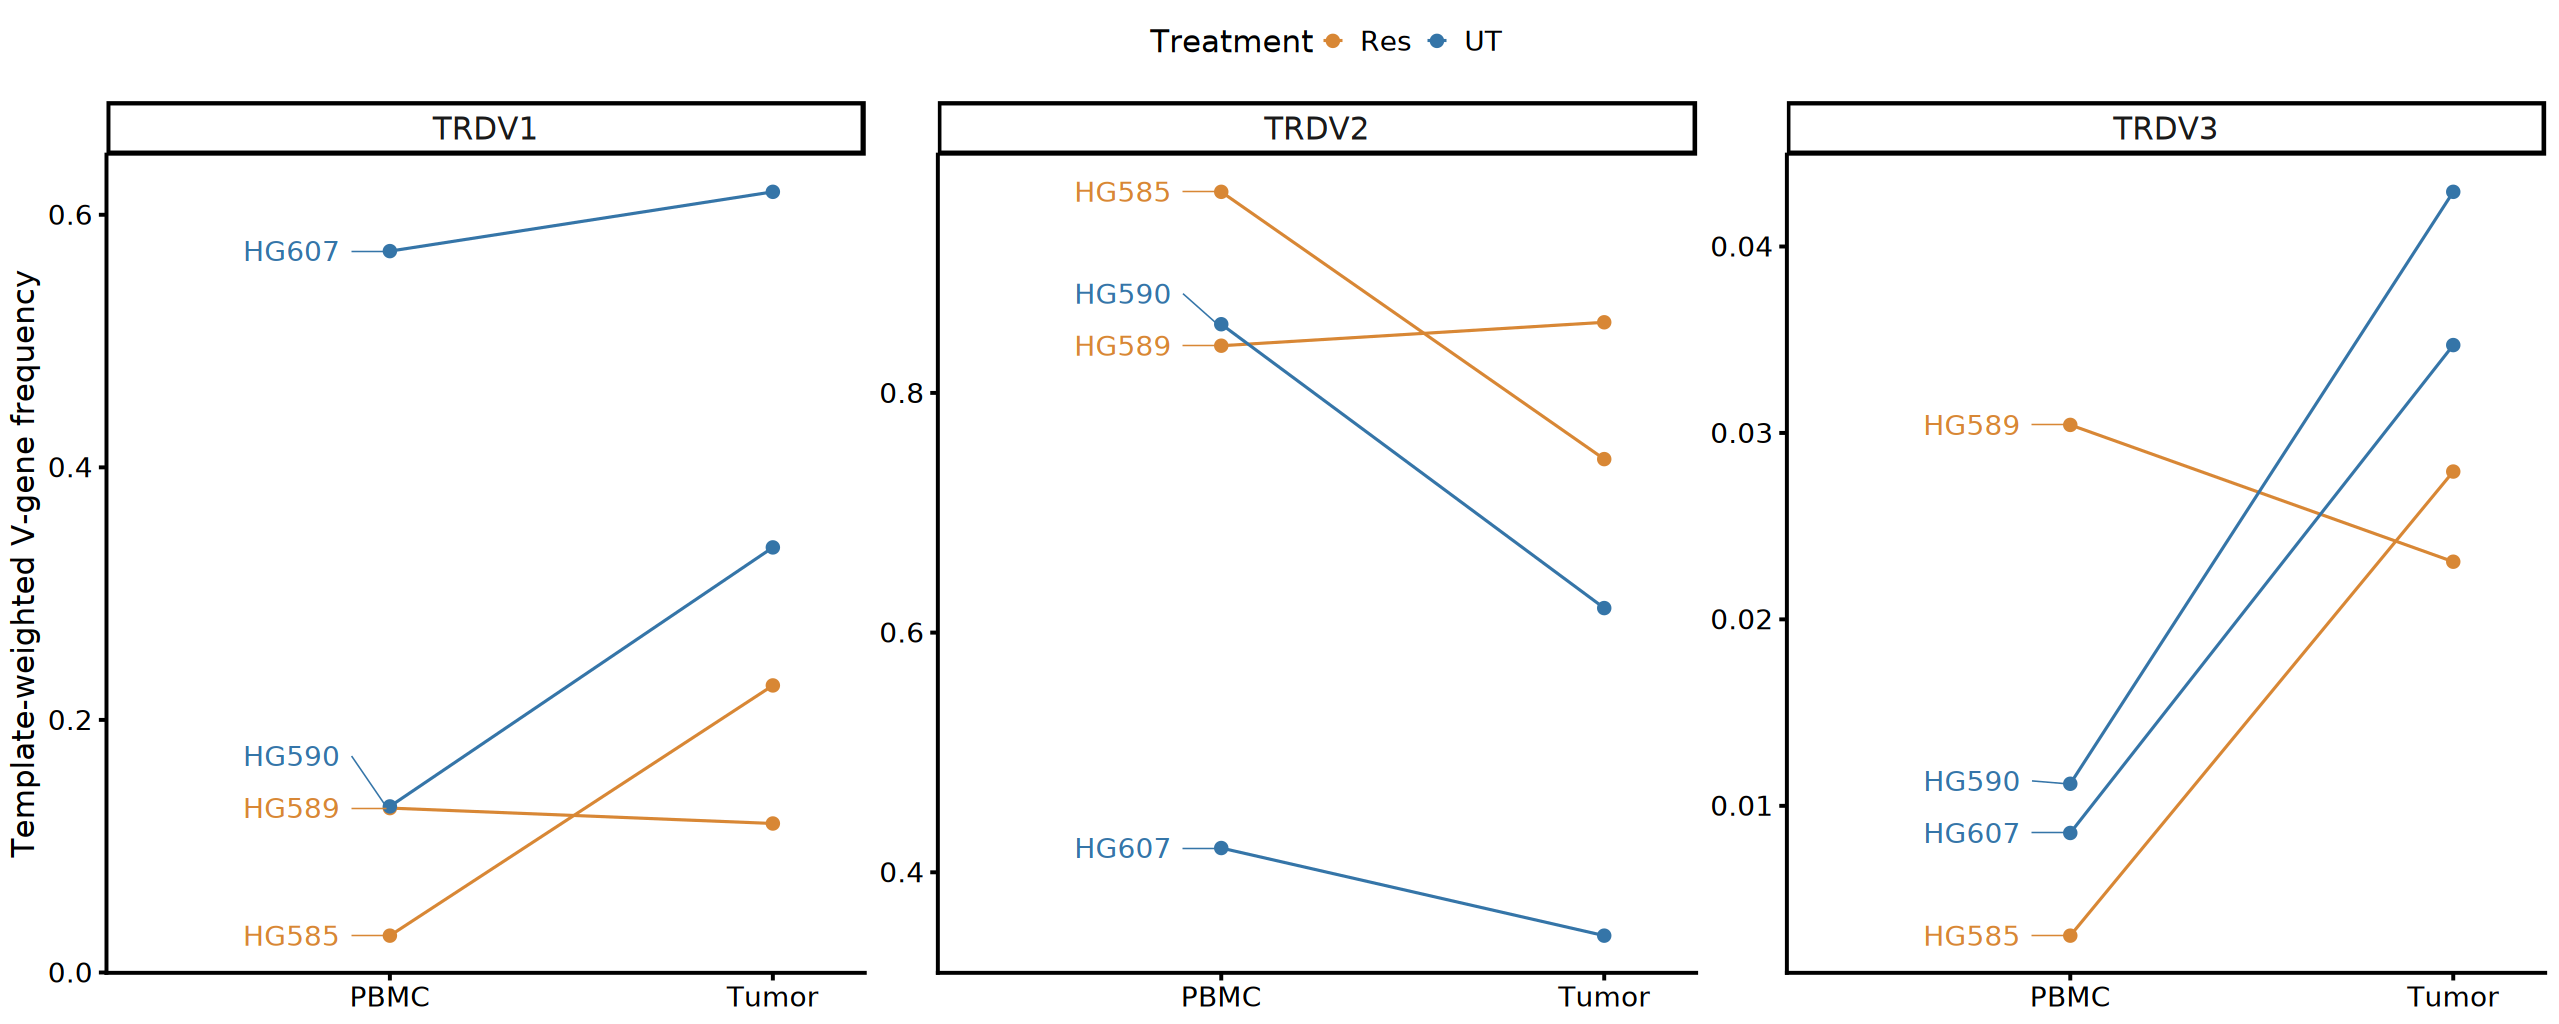

In [19]:
s6 <- observed %>% filter(patient %in% PAIRS) %>% pivot_longer(all_of(GSHORT),names_to="gene",values_to="frequency")
s6_labels <- filter(s6,tissue=="PBMC") %>% arrange(gene,frequency) %>% mutate(label_y=frequency)
for(g in GSHORT) {
    ix <- which(s6_labels$gene==g);min_gap <- diff(range(s6$frequency[s6$gene==g]))*.07
    for(j in 2:length(ix)) s6_labels$label_y[ix[j]] <- max(s6_labels$frequency[ix[j]],s6_labels$label_y[ix[j-1]]+min_gap)
}
plot_S6 <- ggplot(s6,aes(ifelse(tissue=="PBMC",1,2),frequency,group=patient,colour=treatment))+
    geom_line(linewidth=.8)+geom_point(size=3)+
    geom_segment(data=s6_labels,aes(x=.9,xend=.99,y=label_y,yend=frequency),linewidth=.4,show.legend=FALSE)+
    geom_text(data=s6_labels,aes(x=.87,y=label_y,label=patient),hjust=1,size=20/.pt,show.legend=FALSE)+
    scale_colour_manual(values=SUP_COLORS)+scale_x_continuous(breaks=1:2,labels=c("PBMC","Tumor"),limits=c(.35,2.15))+
    facet_wrap(~gene,nrow=1,scales="free_y")+labs(x=NULL,y="Template-weighted V-gene frequency",colour="Treatment")+theme(legend.position="top")
emit_figure("S-TCR6",plot_S6,width=650,height=260,scope="optional",
    caption="S-TCR6 (optional). Template-weighted TRDV1/2/3 frequencies in four matched donors. Lines connect tissues within donor. Exact patient-level tests, six treatment-label permutations, and leave-one-patient-out effects are supplied as source data. These exploratory variable-gene comparisons are not a response to the constant-region usage question.")
patient_statistics

## S-TCR7 - Optional patient-wise VDJ composition

Starting with S-TCR4's within-patient enrichment calls, count each enriched clone once by V/D/J combination. Plot counts and fractions of each patient's enriched total, plus enriched/union fractions. For each VDJ with at least one enriched clone, compare patient-level composition between treatments by exact label permutation, then apply BH across these combinations. These tests are separate from main Figure 3G's pooled clone-count Fisher tests.

In [20]:
vdj_patient <- paired_tests %>% separate(clone_key,into=KEY,sep="\\|",remove=FALSE) %>%
    mutate(VDJ=paste(vGeneName,dGeneName,jGeneName,sep=" / ")) %>%
    group_by(patient,treatment) %>% mutate(total_tumor_enriched=sum(enrichment=="Tumor")) %>%
    group_by(patient,treatment,VDJ) %>% summarise(union_clonotypes=n(),tumor_enriched_clonotypes=sum(enrichment=="Tumor"),
        fraction_of_all_tumor_enriched=sum(enrichment=="Tumor")/max(1,first(total_tumor_enriched)),.groups="drop")
save_table(vdj_patient,"VDJ_patient_summary")
tested_vdj <- vdj_patient %>% group_by(VDJ) %>% summarise(n=sum(tumor_enriched_clonotypes),.groups="drop") %>% filter(n>0) %>% pull(VDJ)
vdj_complete <- expand_grid(patient=PAIRS,VDJ=sort(tested_vdj)) %>%
    left_join(select(vdj_patient,patient,VDJ,fraction_of_all_tumor_enriched),by=c("patient","VDJ")) %>%
    mutate(fraction_of_all_tumor_enriched=replace_na(fraction_of_all_tumor_enriched,0),treatment=ifelse(patient %in% c("HG585","HG589"),"Res","UT"))
vdj_patient_tests <- vdj_complete %>% group_by(VDJ) %>% summarise(
    mean_Res=mean(fraction_of_all_tumor_enriched[treatment=="Res"]),mean_UT=mean(fraction_of_all_tumor_enriched[treatment=="UT"]),
    p_exact=exact_group(fraction_of_all_tumor_enriched[treatment=="Res"],fraction_of_all_tumor_enriched[treatment=="UT"]),.groups="drop") %>%
    mutate(Res_minus_UT_mean=mean_Res-mean_UT,n_Res=2,n_UT=2,q_BH=p.adjust(p_exact,"BH"))
save_main(vdj_patient_tests,"G_patient_level_VDJ_tests")

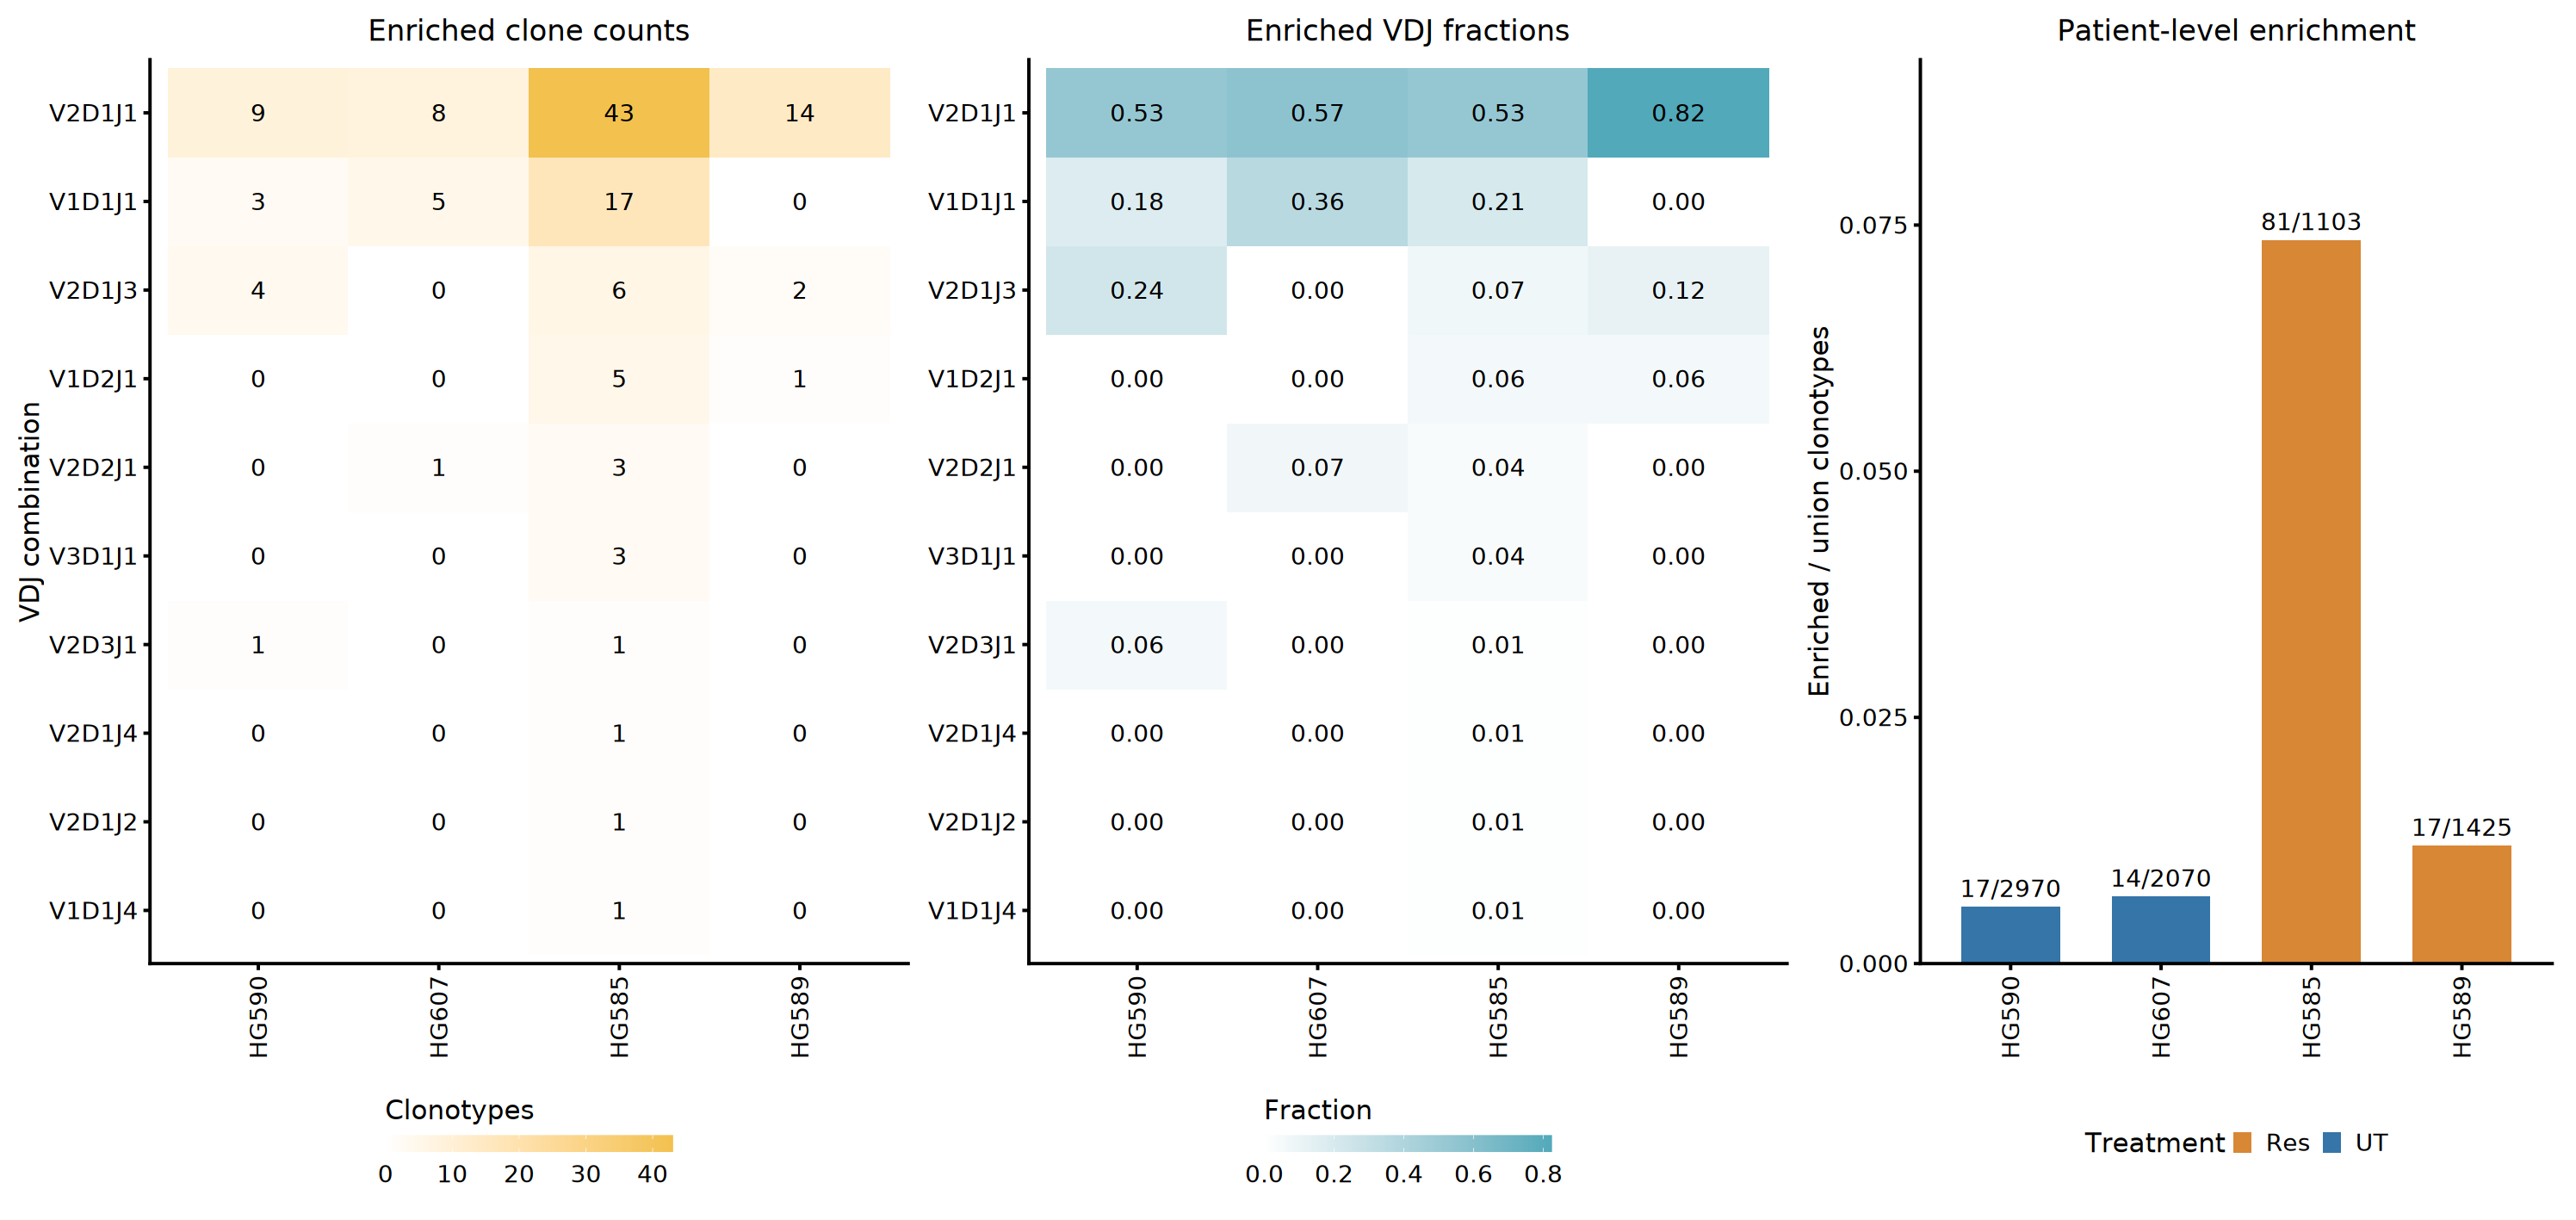

In [21]:
s7_combinations <- vdj_patient %>% group_by(VDJ) %>% summarise(n=sum(tumor_enriched_clonotypes),.groups="drop") %>% filter(n>0) %>% arrange(n,VDJ) %>% pull(VDJ)
short_vdj <- function(x) gsub(" / ","",compact_gene(x))
s7 <- expand_grid(patient=c("HG590","HG607","HG585","HG589"),VDJ=s7_combinations) %>%
    left_join(vdj_patient,by=c("patient","VDJ")) %>% mutate(across(c(tumor_enriched_clonotypes,fraction_of_all_tumor_enriched),~replace_na(.x,0)),
        patient=factor(patient,levels=c("HG590","HG607","HG585","HG589")),VDJ=factor(VDJ,levels=s7_combinations))
s7a <- ggplot(s7,aes(patient,VDJ,fill=tumor_enriched_clonotypes))+geom_tile()+geom_text(aes(label=tumor_enriched_clonotypes),size=20/.pt)+
    scale_fill_gradient(low="white",high="#F2C14E",name="Clonotypes")+scale_y_discrete(labels=short_vdj)+labs(x=NULL,y="VDJ combination",title="Enriched clone counts")+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="bottom")+
    guides(fill=guide_colourbar(barwidth=unit(85,"mm"),barheight=unit(5,"mm"),title.position="top"))
s7b <- ggplot(s7,aes(patient,VDJ,fill=fraction_of_all_tumor_enriched))+geom_tile()+
    geom_text(aes(label=sprintf("%.2f",fraction_of_all_tumor_enriched)),size=20/.pt)+
    scale_fill_gradient(low="white",high="#52A9BA",name="Fraction")+scale_y_discrete(labels=short_vdj)+labs(x=NULL,y=NULL,title="Enriched VDJ fractions")+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="bottom")+
    guides(fill=guide_colourbar(barwidth=unit(85,"mm"),barheight=unit(5,"mm"),title.position="top"))
s7c <- ggplot(patient_correlations,aes(factor(patient,levels=c("HG590","HG607","HG585","HG589")),tumor_enriched_fraction_of_union,fill=treatment))+
    geom_col(width=.65)+geom_text(aes(label=paste0(tumor_enriched_clonotypes,"/",union_clonotypes)),vjust=-.6,size=20/.pt)+
    scale_fill_manual(values=SUP_COLORS)+scale_y_continuous(expand=expansion(mult=c(0,.25)))+
    labs(x=NULL,y="Enriched / union clonotypes",title="Patient-level enrichment",fill="Treatment")+
    theme(axis.text.x=element_text(angle=90,hjust=1,vjust=.5),legend.position="bottom")
emit_figure("S-TCR7",(s7a|s7b|s7c)+plot_layout(widths=c(1.2,1.2,1)),width=760,height=360,scope="optional",
    caption="S-TCR7 (optional). VDJ composition after patient-wise enrichment testing from S-TCR4. Heatmaps show enriched-clone counts and fractions within each patient's enriched repertoire. Bars show tumor-enriched/union fractions, with numerator/denominator labels. Exact patient-label tests with BH across VDJ combinations accompany the figure; these are separate from main Figure 3G clone-count tests.")

## Export legends, provenance, and validation

Save separate text legends, two multipage supplement PDFs, input hashes, package versions, sampling settings, and figure order. Multipage PDFs redraw stored plotting functions at native physical dimensions. Assertions check the cohort, totals, test results, sampling distribution, and complete output set.

In [22]:
combine_supplements <- function(ids,filename) {
    width <- max(vapply(figures[ids],`[[`,numeric(1),"width"));height <- max(vapply(figures[ids],`[[`,numeric(1),"height"))
    cairo_pdf(filename,width=width/25.4,height=height/25.4,family=FONT,onefile=TRUE)
    for(id in ids) {
        f <- figures[[id]];grid.newpage()
        pushViewport(viewport(width=unit(f$width,"mm"),height=unit(f$height,"mm")))
        f$draw(new_page=FALSE);popViewport()
    }
    dev.off();invisible(NULL)
}
combine_supplements(paste0("S-TCR",1:4),file.path(OUT_ROOT,"results/reviewer_requested/Supplementary_TCR_analyses.pdf"))
combine_supplements(paste0("S-TCR",5:7),file.path(OUT_ROOT,"results/optional_analyses/Optional_TCR_analyses.pdf"))
for(scope in c("main","requested","optional")) {
    ids <- names(figures)[vapply(figures,function(f) f$scope==scope,logical(1))]
    sub <- switch(scope,main="main_figure3",requested="reviewer_requested",optional="optional_analyses")
    writeLines(unlist(lapply(ids,function(id) c(id,figures[[id]]$caption,""))),file.path(OUT_ROOT,"results",sub,"figure_legends.txt"))
}
stopifnot(length(figure_order)==15,identical(figure_order,c(paste0("Figure3",LETTERS[1:7]),"Figure3A-G_revised",paste0("S-TCR",1:7))))
stopifnot(B_p==.125,sum(enriched$treatment=="Res")==75,sum(enriched$treatment=="UT")==33)
stopifnot(all(group_counts$union_clonotypes[match(c("Res","UT"),group_counts$treatment)]==c(2528,5040)),
    all(group_counts$tumor_enriched_clonotypes[match(c("Res","UT"),group_counts$treatment)]==c(73,33)))
v2d1j1 <- G_tests[vdj_name(G_tests)=="V2D1J1",]
stopifnot(nrow(v2d1j1)==1,abs(v2d1j1$p_fisher-.1978990804547)<1e-10,all(G_tests$p_fisher>=.05))
stopifnot(nrow(draws)==10*REPS,nrow(ci)==4*REPS,nrow(rarefaction)==50,nrow(patient_statistics)==31,
    nrow(permutations)==6,nrow(loo)==35,length(list.files(file.path(OUT_ROOT,"results"),pattern="[.]pdf$",recursive=TRUE))==17)
packages <- c("IRkernel","dplyr","tidyr","ggplot2","ggalluvial","treemapify","patchwork","jsonlite","digest","ragg")
package_versions <- setNames(lapply(packages,function(p) as.character(packageVersion(p))),packages)
capture.output(sessionInfo(),file=file.path(OUT_ROOT,"logs/sessionInfo.txt"))
write_json_record(list(R=R.version.string,kernel="datascience-r",packages=package_versions,seed=SEED,RNG=RNGkind(),
    iterations=REPS,rarefaction_depth=depth,started_with_empty_output=started_empty,included_samples=samples,
    excluded_samples=as.list(EXCLUDED),paired_patients=PAIRS,raw_inputs=input_manifest,figure_order=figure_order,
    figure_dimensions=figure_audit,treemap_dimensions=treemap_audit),"logs/R_analysis_provenance.json")
write_json_record(list(passed=TRUE,checks=c("12 raw exports; 10 included specimens; 4 pairs","Original annotation filter preserved; productive In only",
    "Main E counts: Res 73/2528 and UT 33/5040","F/G enriched totals: Res 75 and UT 33","Main B P=0.125; V2D1J1 P=0.1978990804547",
    "Sampling totals and per-clone bounds; gene means within six theoretical SE","31 patient-level tests; six label permutations; 35 leave-one-out effects",
    "15 figures in requested order; 17 exported PDFs")),"logs/R_internal_validation.json")
cat("All internal checks passed. Exported 15 figures and 17 PDFs.\n")

All internal checks passed. Exported 15 figures and 17 PDFs.
